# Credit Card Fraud Detection Using Machine Learning

**Author:** Steve Seiler  
**Project:** Credit Card Fraud Detection

This notebook provides an end-to-end framework for detecting fraudulent credit card transactions in a highly imbalanced dataset. It compares Logistic Regression, Random Forest, Support Vector Machine (SVM), and XGBoost while evaluating resampling methods such as SMOTE, Random Under-Sampling, and SMOTE-Tomek. Performance is evaluated with precision, recall, F1-score, ROC-AUC, PR-AUC, Matthews Correlation Coefficient (MCC), and confusion matrices. SHAP is included as an optional interpretability step for the final tree-based model.


## 1. Research Question

How effectively can Logistic Regression, Random Forest, SVM, and XGBoost classify fraudulent and legitimate transactions within a highly imbalanced dataset, and how do sampling and threshold-optimization strategies affect fraud-detection performance?


## 2. Setup

If a package is missing, install it in your Jupyter environment before running the notebook. The main packages used are pandas, numpy, matplotlib, seaborn, scikit-learn, imbalanced-learn, xgboost, and shap.


In [1]:
# ================================================================
# STEP 2: PROJECT SETUP
# CREDIT CARD FRAUD DETECTION USING MACHINE LEARNING
# ================================================================

# PURPOSE OF THIS CELL:
#
# This cell prepares the Python environment for the entire project.
# Think of this section as getting all of the tools ready before
# starting the actual credit card fraud analysis.
#
# This cell does NOT train a machine learning model yet.
#
# Instead, this cell:
#
# 1. Loads tools for working with the dataset.
# 2. Loads tools for creating graphs.
# 3. Loads machine learning algorithms.
# 4. Loads tools for handling the class imbalance.
# 5. Loads tools for measuring model performance.
# 6. Checks whether XGBoost is installed and available.
#
# If this cell runs successfully, the notebook is ready to move
# to the next step: loading the creditcard.csv dataset.


# ================================================================
# SECTION 1: INSTALL PACKAGES IF NEEDED
# ================================================================

# The following line is commented out because the packages
# should only need to be installed once.
#
# If Python reports that one of these packages is missing,
# remove the # symbol from the next line and run the cell.
#
# pandas:
# Used for loading and working with the credit card dataset.
#
# numpy:
# Used for mathematical and numerical calculations.
#
# matplotlib:
# Used for creating graphs and charts.
#
# seaborn:
# Used for statistical graphs and confusion matrix heatmaps.
#
# scikit-learn:
# Contains machine learning models and evaluation tools.
#
# imbalanced-learn:
# Contains SMOTE and other techniques for imbalanced datasets.
#
# xgboost:
# Contains the XGBoost machine learning algorithm.
#
# shap:
# Helps explain how individual features affect model predictions.

# %pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn xgboost shap


# ================================================================
# SECTION 2: WARNING MESSAGES
# ================================================================

# Import Python's warning-management library.
import warnings

# Hide non-critical warning messages.
#
# This makes the notebook output easier to read.
# A warning is different from an error. Errors will still stop
# the code when something is actually wrong.
warnings.filterwarnings('ignore')


# ================================================================
# SECTION 3: DATA ANALYSIS TOOLS
# ================================================================

# Import NumPy.
#
# NumPy is used for mathematical operations and working with
# numerical values.
#
# "np" is the standard short name for NumPy.
import numpy as np


# Import pandas.
#
# pandas is one of the most important libraries in this project.
#
# The creditcard.csv file will be loaded into a pandas DataFrame.
#
# A DataFrame can be thought of as a spreadsheet containing
# rows and columns.
#
# In our dataset:
#
# ROW = One credit card transaction
#
# COLUMN = A characteristic or feature of the transaction
#
# Examples of columns include:
# Time
# V1 through V28
# Amount
# Class
#
# "pd" is the standard short name for pandas.
import pandas as pd


# ================================================================
# SECTION 4: GRAPHING TOOLS
# ================================================================

# Import Matplotlib.
#
# Matplotlib will allow us to create visualizations such as:
#
# - Transaction distributions
# - ROC curves
# - Precision-Recall curves
# - Model comparison graphs
#
# "plt" is the commonly used short name for pyplot.
import matplotlib.pyplot as plt


# Import Seaborn.
#
# Seaborn works with Matplotlib and makes many statistical
# visualizations easier to create.
#
# We can use it for:
#
# - Class distribution graphs
# - Box plots
# - Histograms
# - Confusion matrix heatmaps
#
# "sns" is the standard short name for Seaborn.
import seaborn as sns


# ================================================================
# SECTION 5: TRAINING AND TESTING DATA
# ================================================================

# Import train_test_split.
#
# A machine learning model should not be trained and evaluated
# using exactly the same observations.
#
# We will therefore divide our dataset into:
#
# TRAINING DATA
# Used to teach the machine learning model.
#
# TEST DATA
# Used to evaluate the model on transactions that were not used
# to train the model.
#
# This provides a better test of how the model performs on
# previously unseen data.
from sklearn.model_selection import train_test_split


# ================================================================
# SECTION 6: DATA STANDARDIZATION
# ================================================================

# Import StandardScaler.
#
# Some numerical variables can be measured on very different scales.
#
# StandardScaler transforms selected numerical variables so their
# scales are more comparable.
#
# Scaling is particularly useful for algorithms such as:
#
# - Logistic Regression
# - Support Vector Machine
from sklearn.preprocessing import StandardScaler


# ================================================================
# SECTION 7: COLUMN PREPROCESSING
# ================================================================

# Import ColumnTransformer.
#
# ColumnTransformer allows us to apply different preprocessing
# operations to different columns.
#
# For example, we can scale Time and Amount while handling the
# PCA-transformed V1 through V28 features separately.
from sklearn.compose import ColumnTransformer


# ================================================================
# SECTION 8: MACHINE LEARNING PIPELINE
# ================================================================

# Import Pipeline.
#
# A pipeline allows us to connect multiple steps into one
# organized machine learning process.
#
# A simplified example is:
#
# Credit Card Data
#        |
#        v
# Preprocessing
#        |
#        v
# Machine Learning Model
#        |
#        v
# Fraud Predictions
#
# This makes the experiment more organized and repeatable.
from sklearn.pipeline import Pipeline


# ================================================================
# SECTION 9: LOGISTIC REGRESSION
# ================================================================

# Import Logistic Regression.
#
# Logistic Regression will be used as one of our classification
# models.
#
# The model will attempt to predict:
#
# Class 0 = Legitimate transaction
# Class 1 = Fraudulent transaction
#
# Logistic Regression provides a useful baseline model that can
# be compared with the more complex models.
from sklearn.linear_model import LogisticRegression


# ================================================================
# SECTION 10: RANDOM FOREST
# ================================================================

# Import Random Forest.
#
# Random Forest creates multiple decision trees and combines
# their predictions.
#
# We will test how effectively Random Forest distinguishes
# fraudulent transactions from legitimate transactions.
from sklearn.ensemble import RandomForestClassifier


# ================================================================
# SECTION 11: SUPPORT VECTOR MACHINE
# ================================================================

# Import Support Vector Classifier (SVC).
#
# SVC is scikit-learn's Support Vector Machine classifier.
#
# The model attempts to create a decision boundary that separates:
#
# Class 0 = Legitimate transactions
#
# from
#
# Class 1 = Fraudulent transactions
from sklearn.svm import SVC


# ================================================================
# SECTION 12: MODEL EVALUATION
# ================================================================

# Import the measurements that will be used to evaluate how well
# each machine learning model performs.
#
# Accuracy by itself is not enough for this project because the
# fraud class is much smaller than the legitimate class.

from sklearn.metrics import (

    # Produces an overall classification summary.
    classification_report,

    # Shows correct and incorrect predictions.
    confusion_matrix,

    # PRECISION:
    # Of the transactions predicted as fraud, how many were
    # actually fraudulent?
    precision_score,

    # RECALL:
    # Of all actual fraudulent transactions, how many did the
    # model successfully detect?
    #
    # Recall is particularly important when missed fraud cases
    # are a major concern.
    recall_score,

    # F1-SCORE:
    # Combines precision and recall into one measurement.
    f1_score,

    # ROC-AUC:
    # Evaluates how effectively the model separates the two
    # classes across classification thresholds.
    roc_auc_score,

    # AVERAGE PRECISION:
    # Summarizes performance related to the Precision-Recall curve.
    #
    # Precision-Recall evaluation is especially useful when
    # examining a rare positive class such as fraud.
    average_precision_score,

    # MCC:
    # Matthews Correlation Coefficient provides another measure
    # of binary classification performance.
    matthews_corrcoef,

    # Creates the ROC curve.
    RocCurveDisplay,

    # Creates the Precision-Recall curve.
    PrecisionRecallDisplay
)


# ================================================================
# SECTION 13: IMBALANCED DATA HANDLING
# ================================================================

# One of the main challenges of this project is CLASS IMBALANCE.
#
# The dataset contains many legitimate transactions and far fewer
# fraudulent transactions.
#
# We will compare several techniques for dealing with this issue.


# SMOTE
# ------------------------------------------------
#
# SMOTE stands for:
# Synthetic Minority Over-sampling Technique.
#
# SMOTE creates synthetic examples based on minority-class
# observations.
#
# In this project:
#
# Minority class = Fraudulent transactions
#
# The goal is to give the model more minority-class information
# during training.
from imblearn.over_sampling import SMOTE


# RANDOM UNDER-SAMPLING
# ------------------------------------------------
#
# Instead of increasing the minority class, Random Under-Sampling
# reduces the number of majority-class observations used during
# training.
#
# Majority class = Legitimate transactions
#
# Minority class = Fraudulent transactions
from imblearn.under_sampling import RandomUnderSampler


# SMOTE-TOMEK
# ------------------------------------------------
#
# SMOTE-Tomek combines an oversampling technique with a
# data-cleaning technique.
#
# We will compare this approach with regular SMOTE and
# Random Under-Sampling.
from imblearn.combine import SMOTETomek


# ================================================================
# SECTION 14: IMBALANCED-LEARN PIPELINE
# ================================================================

# Import the pipeline provided by imbalanced-learn.
#
# We rename it ImbPipeline so it is easy to distinguish from
# scikit-learn's regular Pipeline.
#
# This pipeline allows us to organize steps such as:
#
# Original Training Data
#          |
#          v
# Preprocessing
#          |
#          v
# SMOTE / Under-Sampling / SMOTE-Tomek
#          |
#          v
# Machine Learning Model
#          |
#          v
# Predictions
#
# A major benefit is that the sampling operation can remain part
# of the training workflow rather than being applied to the
# held-out test data.
from imblearn.pipeline import Pipeline as ImbPipeline


# ================================================================
# SECTION 15: XGBOOST
# ================================================================

# XGBoost is another machine learning algorithm that will be
# compared with:
#
# - Logistic Regression
# - Random Forest
# - Support Vector Machine
#
# We use try/except because XGBoost is installed separately from
# scikit-learn.
#
# Python will first TRY to import XGBoost.

try:

    # Import the XGBoost classifier.
    from xgboost import XGBClassifier

    # If this line is reached, XGBoost imported successfully.
    XGBOOST_AVAILABLE = True


# If XGBoost cannot be imported, Python will execute this section
# instead of stopping the entire notebook.
except ImportError:

    # Record that XGBoost is unavailable.
    XGBOOST_AVAILABLE = False

    # Tell the user what happened.
    print(
        "XGBoost is not installed. "
        "Run the install cell above if you want to use it."
    )


# ================================================================
# SECTION 16: REPRODUCIBLE RESULTS
# ================================================================

# Set a fixed random state.
#
# Some machine learning operations use random processes.
#
# Using the same random state helps make those random operations
# behave consistently when the notebook is rerun with the same
# data and settings.
#
# The number 42 is simply the fixed value chosen for this project.
RANDOM_STATE = 42


# ================================================================
# SECTION 17: PANDAS DISPLAY SETTINGS
# ================================================================

# Allow pandas to display up to 50 columns.
#
# This is useful because our credit card dataset contains many
# columns, including V1 through V28.
#
# Without this setting, pandas might hide some columns and replace
# them with "...".
pd.set_option('display.max_columns', 50)


# ================================================================
# SECTION 18: VERIFY THAT EVERYTHING LOADED
# ================================================================

# The following commands give us visible confirmation that the
# setup cell actually finished.
#
# Most Python import statements do NOT display anything when they
# work correctly.
#
# Therefore, these messages make it easier to verify that the
# notebook is ready for the next step.


# Confirm that the main Python libraries loaded.
print("Python libraries loaded successfully.")


# Show whether XGBoost is available.
print("XGBoost available:", XGBOOST_AVAILABLE)


# Provide a more detailed XGBoost message.
if XGBOOST_AVAILABLE:

    # This message should appear after XGBoost has been installed
    # correctly.
    print("XGBoost loaded successfully and is ready to use.")

else:

    # This message appears if Python still cannot import XGBoost.
    print("XGBoost is NOT available. Check the XGBoost installation.")


# Final confirmation that Python reached the end of the setup cell.
print("Project setup completed successfully.")

Python libraries loaded successfully.
XGBoost available: True
XGBoost loaded successfully and is ready to use.
Project setup completed successfully.


## 3. Load the Dataset

Place the Kaggle `creditcard.csv` file in the same folder as this notebook, or update `DATA_PATH` to point to its location. The code deliberately does not download or fabricate the dataset.


In [2]:
# ================================================================
# STEP 3: LOAD THE CREDIT CARD FRAUD DATASET
# ================================================================

# PURPOSE OF THIS CELL:
#
# This section loads the credit card transaction dataset into
# Python so that we can begin analyzing the data.
#
# The dataset is stored in a CSV file named:
#
# creditcard.csv
#
# CSV stands for:
#
# Comma-Separated Values
#
# A CSV file stores information in rows and columns, similar
# to a spreadsheet.
#
# After Python loads the file, pandas will store the information
# inside something called a DataFrame.
#
# A pandas DataFrame can be thought of as a table or spreadsheet
# that Python can analyze.


# ================================================================
# SECTION 1: TELL PYTHON WHERE THE DATASET IS LOCATED
# ================================================================

# DATA_PATH is a variable that stores the name and location
# of our credit card dataset.
#
# In this example, the file name is:
#
# creditcard.csv
#
# Because only the file name is provided, Python will look for
# creditcard.csv in the current working folder used by the
# Jupyter Notebook.
#
# The spelling of the file name must match the actual file.
DATA_PATH = 'creditcard.csv'


# ================================================================
# SECTION 2: LOAD THE CSV FILE
# ================================================================

# Use pandas to read the CSV file.
#
# pd.read_csv() means:
#
# pd
#   = pandas
#
# read_csv
#   = read information from a CSV file
#
# DATA_PATH
#   = tells pandas which CSV file to open
#
# The information loaded from creditcard.csv will be stored
# in a variable named "df".
#
# "df" is short for DataFrame.
#
# From this point forward, whenever we use:
#
# df
#
# we are referring to the credit card transaction dataset.
df = pd.read_csv(DATA_PATH)


# ================================================================
# SECTION 3: CONFIRM THAT THE DATASET LOADED
# ================================================================

# Display a confirmation message.
#
# If Python reaches this line without an error, pandas was able
# to read the CSV file.
print("Credit card dataset loaded successfully.")


# ================================================================
# SECTION 4: DISPLAY THE SIZE OF THE DATASET
# ================================================================

# df.shape tells us the size of the DataFrame.
#
# The result contains two numbers:
#
# (number of rows, number of columns)
#
# ROW:
# Each row represents one transaction in the dataset.
#
# COLUMN:
# Each column represents one variable or feature associated
# with the transactions.
#
# For example, the dataset contains variables such as:
#
# Time
# V1 through V28
# Amount
# Class
#
# Printing the shape allows us to verify how much data was loaded.
print("\nDataset shape:")
print(df.shape)


# ================================================================
# SECTION 5: DISPLAY THE NUMBER OF ROWS
# ================================================================

# len(df) counts the number of rows in the DataFrame.
#
# This gives us the total number of transaction records
# that Python loaded from the CSV file.
print("\nNumber of transactions:")
print(len(df))


# ================================================================
# SECTION 6: DISPLAY THE NUMBER OF COLUMNS
# ================================================================

# df.shape[1] gives us the number of columns.
#
# In Python:
#
# df.shape[0] = number of rows
# df.shape[1] = number of columns
print("\nNumber of columns:")
print(df.shape[1])


# ================================================================
# SECTION 7: DISPLAY THE COLUMN NAMES
# ================================================================

# Display the names of all variables in the dataset.
#
# .columns gets the column names.
#
# .tolist() converts the column names into a regular Python list
# that is easy to read.
print("\nColumn names:")
print(df.columns.tolist())


# ================================================================
# SECTION 8: DISPLAY THE FIRST FIVE TRANSACTIONS
# ================================================================

# df.head() displays the first five rows of the dataset by default.
#
# This gives us a quick visual check of the information that
# Python loaded.
#
# We can inspect the:
#
# Time column
# V1 through V28 PCA-transformed features
# Amount column
# Class column
#
# At this point, we are only examining the data.
#
# We are NOT training a machine learning model yet.
print("\nFirst five transactions:")

display(df.head())


# ================================================================
# SECTION 9: EXPLAIN THE CLASS COLUMN
# ================================================================

# The Class column will eventually become the TARGET variable
# for our machine learning models.
#
# The model will try to predict the value of this column.
#
# For this dataset:
#
# Class 0 = Legitimate transaction
#
# Class 1 = Fraudulent transaction
#
# Later in the notebook, we will examine how many observations
# belong to each class.


# ================================================================
# STEP 3 COMPLETE
# ================================================================

# Display a final confirmation message showing that Python reached
# the end of this section without encountering an error.
print("\nStep 3 completed successfully.")
print("The credit card dataset is now ready for analysis.")

Credit card dataset loaded successfully.

Dataset shape:
(284807, 31)

Number of transactions:
284807

Number of columns:
31

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

First five transactions:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Step 3 completed successfully.
The credit card dataset is now ready for analysis.


## 4. Initial Data Quality Checks


In [3]:
# ================================================================
# STEP 4: INITIAL DATA QUALITY CHECKS
# ================================================================
 
# Display a heading for the column names.
print('Columns:')
 
# Display all column names from the dataset.
print(df.columns.tolist())
 
 
# Display a heading for the data types.
print('\nData types:')
 
# Display the data type of every column.
print(df.dtypes)
 
 
# Display a heading for missing values.
print('\nMissing values:')
 
# Count all missing values in the dataset.
print(int(df.isna().sum().sum()))
 
 
# Display a heading for duplicate rows.
print('\nDuplicate rows:')
 
# Count the number of duplicated rows in the dataset.
print(int(df.duplicated().sum()))
 
 
# Confirm that this section finished successfully.
print('\nInitial data quality check completed successfully.')

Columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Data types:
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

Missing values:
0

Duplicate rows:
1081

Initial data quality check completed successfully.


## 5. Class Distribution

The fraud class is expected to be rare, so class counts and percentages should be examined before modeling.


Credit Card Transaction Class Distribution:



,Count,Percent,Transaction Type
Class,,,
0,284315,99.827251,Legitimate
1,492,0.172749,Fraud


Total number of transactions:
284,807

Legitimate transactions:
284,315
Percentage legitimate:
99.8273%

Fraudulent transactions:
492
Percentage fraudulent:
0.1727%

Class imbalance ratio:
There are approximately 577.9 legitimate transactions for every fraudulent transaction.


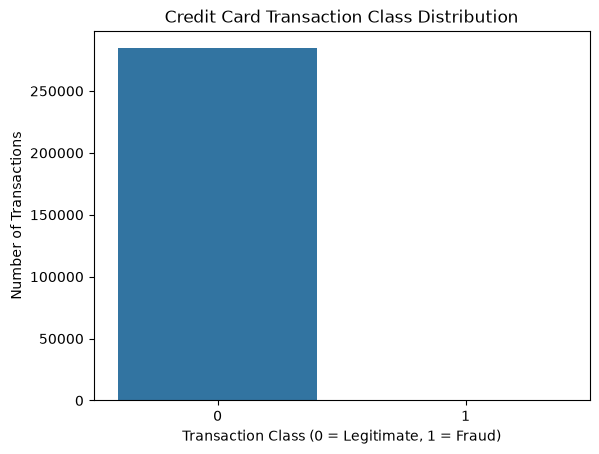


Step 5 completed successfully.
The dataset is highly imbalanced, so future model evaluation should focus on fraud-sensitive performance measurements.


In [4]:
# ================================================================
# STEP 5: EXAMINE THE CLASS DISTRIBUTION
# ================================================================

# PURPOSE OF THIS CELL:
#
# This section examines how many transactions belong to each
# category in the credit card fraud dataset.
#
# The target column in our dataset is named:
#
# Class
#
# The Class column contains two possible values:
#
# Class 0 = Legitimate transaction
# Class 1 = Fraudulent transaction
#
# Before training machine learning models, it is important to
# understand how many examples belong to each class.
#
# In this dataset, we expect the number of legitimate transactions
# to be much larger than the number of fraudulent transactions.
#
# This situation is called:
#
# CLASS IMBALANCE
#
# Class imbalance is important because a machine learning model
# could appear to perform very well simply because the majority
# of transactions are legitimate.
#
# Therefore, later in the project we will use measurements such as:
#
# Precision
# Recall
# F1-score
# ROC-AUC
# PR-AUC
# Matthews Correlation Coefficient (MCC)
#
# We will also investigate sampling methods such as:
#
# SMOTE
# Random Under-Sampling
# SMOTE-Tomek


# ================================================================
# SECTION 1: COUNT EACH TRANSACTION CLASS
# ================================================================

# Select the Class column from our DataFrame.
#
# df['Class']
#
# represents the target variable that tells us whether each
# transaction is legitimate or fraudulent.
#
# value_counts() counts how many times each Class value appears.
#
# sort_index() puts the classes in numerical order:
#
# 0 first
# 1 second

class_counts = df['Class'].value_counts().sort_index()


# ================================================================
# SECTION 2: CALCULATE CLASS PERCENTAGES
# ================================================================

# We also want to know what percentage of the entire dataset
# belongs to each class.
#
# normalize=True changes value_counts() from a raw count into
# a proportion.
#
# For example:
#
# 0.50 would mean 50%
#
# Multiplying the result by 100 converts the proportion into
# a percentage that is easier to understand.

class_pct = (
    df['Class']
    .value_counts(normalize=True)
    .sort_index()
    * 100
)


# ================================================================
# SECTION 3: CREATE A SUMMARY TABLE
# ================================================================

# Create a new pandas DataFrame containing:
#
# Count
#     The number of transactions in each class.
#
# Percent
#     The percentage of the entire dataset represented by
#     each class.
#
# This makes the results easier to read and compare.

class_summary = pd.DataFrame({
    'Count': class_counts,
    'Percent': class_pct
})


# ================================================================
# SECTION 4: LABEL THE CLASSES
# ================================================================

# Add a descriptive column so that the numeric class values
# are easier to understand.
#
# Class 0 = Legitimate
# Class 1 = Fraud

class_summary['Transaction Type'] = [
    'Legitimate',
    'Fraud'
]


# ================================================================
# SECTION 5: DISPLAY THE RESULTS
# ================================================================

# Display a title before showing the table.

print("Credit Card Transaction Class Distribution:")
print()


# Display the class summary table.

display(class_summary)


# ================================================================
# SECTION 6: STORE IMPORTANT VALUES
# ================================================================

# Save the legitimate transaction count.
#
# .loc[0] means:
# Find the row corresponding to Class 0.

legitimate_count = class_counts.loc[0]


# Save the fraudulent transaction count.
#
# .loc[1] means:
# Find the row corresponding to Class 1.

fraud_count = class_counts.loc[1]


# Save the legitimate transaction percentage.

legitimate_percent = class_pct.loc[0]


# Save the fraud percentage.

fraud_percent = class_pct.loc[1]


# ================================================================
# SECTION 7: PRINT THE RESULTS IN PLAIN ENGLISH
# ================================================================

# Print the total number of transactions.
#
# len(df) counts all rows in the dataset.

print("Total number of transactions:")
print(f"{len(df):,}")


# Print the number of legitimate transactions.

print("\nLegitimate transactions:")
print(f"{legitimate_count:,}")


# Print the percentage of legitimate transactions.

print("Percentage legitimate:")
print(f"{legitimate_percent:.4f}%")


# Print the number of fraudulent transactions.

print("\nFraudulent transactions:")
print(f"{fraud_count:,}")


# Print the percentage of fraudulent transactions.

print("Percentage fraudulent:")
print(f"{fraud_percent:.4f}%")


# ================================================================
# SECTION 8: EXPLAIN THE CLASS IMBALANCE
# ================================================================

# Calculate how many legitimate transactions exist for each
# fraudulent transaction.
#
# This helps us describe the class imbalance in an easy-to-
# understand way.

imbalance_ratio = legitimate_count / fraud_count


# Display the approximate imbalance ratio.

print("\nClass imbalance ratio:")
print(
    f"There are approximately {imbalance_ratio:.1f} "
    "legitimate transactions for every fraudulent transaction."
)


# ================================================================
# SECTION 9: CREATE A CLASS DISTRIBUTION GRAPH
# ================================================================

# Create a bar chart showing the number of transactions in
# each class.
#
# sns.countplot() counts how many observations belong to each
# category and displays those counts as bars.

ax = sns.countplot(
    data=df,
    x='Class'
)


# Give the graph a descriptive title.

ax.set_title(
    'Credit Card Transaction Class Distribution'
)


# Label the horizontal axis.
#
# This reminds the reader what 0 and 1 represent.

ax.set_xlabel(
    'Transaction Class (0 = Legitimate, 1 = Fraud)'
)


# Label the vertical axis.

ax.set_ylabel(
    'Number of Transactions'
)


# Display the graph.

plt.show()


# ================================================================
# STEP 5 COMPLETE
# ================================================================

# Display a final message confirming that the class-distribution
# analysis completed successfully.

print("\nStep 5 completed successfully.")

print(
    "The dataset is highly imbalanced, so future model evaluation "
    "should focus on fraud-sensitive performance measurements."
)

## 6. Exploratory Data Analysis

The following cells summarize `Amount` and `Time` and compare transaction amounts by class.


Summary Statistics for Time and Amount:



,Time,Amount
count,284807.000000,284807.000000
mean,94813.859575,88.349619
std,47488.145955,250.120109
min,0.000000,0.000000
25%,54201.500000,5.600000
50%,84692.000000,22.000000
75%,139320.500000,77.165000
max,172792.000000,25691.160000



Transaction Amount Information:
Average transaction amount: 88.35
Median transaction amount:  22.00
Minimum transaction amount: 0.00
Maximum transaction amount: 25,691.16

Transaction Amount Statistics by Class:
Class 0 = Legitimate | Class 1 = Fraud



,Transaction Count,Mean Amount,Median Amount,Minimum Amount,Maximum Amount
Class,,,,,
0,284315,88.291022,22.00,0.0,25691.16
1,492,122.211321,9.25,0.0,2125.87


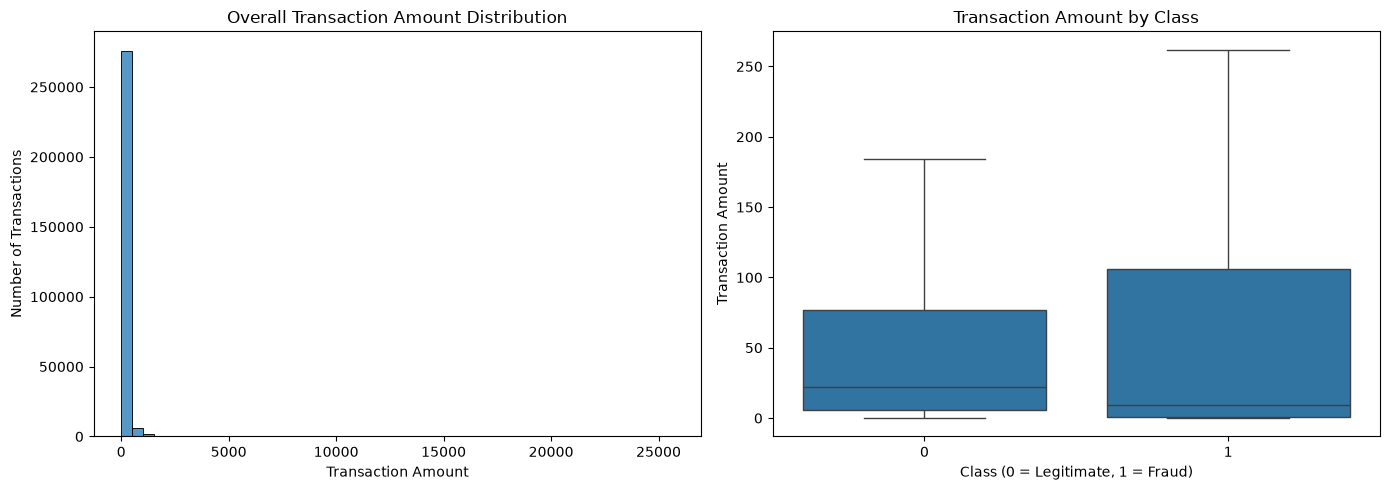


Step 6 completed successfully.
Summary statistics and transaction amount visualizations have been generated.
Next, the dataset can be prepared for machine learning training and testing.


In [5]:
# ================================================================
# STEP 6: EXPLORATORY DATA ANALYSIS (EDA)
# ================================================================

# PURPOSE OF THIS CELL:
#
# Exploratory Data Analysis, commonly called EDA, is the process
# of examining a dataset before building machine learning models.
#
# The goal is to better understand the data by looking at:
#
# 1. Typical values
# 2. Minimum and maximum values
# 3. Average values
# 4. How spread out the values are
# 5. Unusual or extreme values
# 6. Differences between legitimate and fraudulent transactions
#
# In this section, we will focus primarily on two columns:
#
# Time
# Amount
#
# We will also use the Class column to compare legitimate and
# fraudulent transactions.
#
# Remember:
#
# Class 0 = Legitimate transaction
# Class 1 = Fraudulent transaction


# ================================================================
# SECTION 1: EXAMINE TIME AND AMOUNT
# ================================================================

# Display a heading explaining what will be shown next.

print("Summary Statistics for Time and Amount:")
print()


# Select the Time and Amount columns from the DataFrame.
#
# df[['Time', 'Amount']]
#
# tells pandas that we want to work with these two columns.
#
# The describe() function creates a statistical summary.
#
# The summary normally includes:
#
# count
#     Number of observations.
#
# mean
#     The mathematical average.
#
# std
#     Standard deviation.
#     This tells us how spread out the values are.
#
# min
#     Smallest value.
#
# 25%
#     First quartile.
#     Approximately 25% of observations fall at or below this value.
#
# 50%
#     Median value.
#     Half of observations fall below and half above this value.
#
# 75%
#     Third quartile.
#     Approximately 75% of observations fall at or below this value.
#
# max
#     Largest value.

summary_statistics = df[['Time', 'Amount']].describe()


# Display the statistical summary.

display(summary_statistics)


# ================================================================
# SECTION 2: EXPLAIN THE AMOUNT COLUMN
# ================================================================

# The Amount column represents the transaction amount.
#
# Looking at this variable helps us understand:
#
# - The average transaction amount
# - Small transaction amounts
# - Large transaction amounts
# - How widely transaction amounts vary
#
# This is useful because later we want to determine whether
# transaction amount contributes useful information when detecting
# fraudulent transactions.

print("\nTransaction Amount Information:")


# Calculate the average transaction amount.
#
# mean() calculates the arithmetic average.

average_amount = df['Amount'].mean()


# Find the median transaction amount.
#
# The median is the middle value when transaction amounts
# are arranged from smallest to largest.
#
# The median can be especially helpful when a small number of very
# large transactions make the average less representative.

median_amount = df['Amount'].median()


# Find the smallest transaction amount.

minimum_amount = df['Amount'].min()


# Find the largest transaction amount.

maximum_amount = df['Amount'].max()


# Display the results using two decimal places.
#
# :,.2f means:
#
# ,    = display commas for large numbers
# .2f  = display two decimal places

print(f"Average transaction amount: {average_amount:,.2f}")
print(f"Median transaction amount:  {median_amount:,.2f}")
print(f"Minimum transaction amount: {minimum_amount:,.2f}")
print(f"Maximum transaction amount: {maximum_amount:,.2f}")


# ================================================================
# SECTION 3: COMPARE AMOUNTS BY TRANSACTION CLASS
# ================================================================

# Next, compare transaction amounts for the two classes.
#
# Class 0 = Legitimate
# Class 1 = Fraud
#
# groupby('Class') separates the dataset into the two groups.
#
# ['Amount'] tells pandas that we want to examine transaction
# amounts within each group.
#
# agg() calculates several statistics for each class.

amount_by_class = (
    df.groupby('Class')['Amount']
      .agg(['count', 'mean', 'median', 'min', 'max'])
)


# Rename the columns so they are easier to understand.

amount_by_class.columns = [
    'Transaction Count',
    'Mean Amount',
    'Median Amount',
    'Minimum Amount',
    'Maximum Amount'
]


# Display the comparison table.

print("\nTransaction Amount Statistics by Class:")
print("Class 0 = Legitimate | Class 1 = Fraud")
print()

display(amount_by_class)


# ================================================================
# SECTION 4: CREATE TWO VISUALIZATIONS
# ================================================================

# Now we will create two graphs side by side.
#
# GRAPH 1:
# Histogram showing the overall distribution of Amount.
#
# GRAPH 2:
# Box plot comparing Amount between legitimate and fraudulent
# transactions.


# Create an area containing one row and two graphs.
#
# 1 = one row
# 2 = two graph positions
#
# figsize=(14, 5) controls the overall size.

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)


# ================================================================
# SECTION 5: TRANSACTION AMOUNT HISTOGRAM
# ================================================================

# A histogram separates numerical values into ranges and shows
# how many observations fall within each range.
#
# This visualization helps us understand the overall shape of
# the Amount variable.

sns.histplot(
    data=df,
    x='Amount',
    bins=50,
    ax=axes[0]
)


# Give the first graph a title.

axes[0].set_title(
    'Overall Transaction Amount Distribution'
)


# Label the horizontal axis.

axes[0].set_xlabel(
    'Transaction Amount'
)


# Label the vertical axis.

axes[0].set_ylabel(
    'Number of Transactions'
)


# ================================================================
# SECTION 6: TRANSACTION AMOUNT BOX PLOT
# ================================================================

# Create a box plot comparing transaction amounts by Class.
#
# x='Class'
#     Places Class 0 and Class 1 on the horizontal axis.
#
# y='Amount'
#     Compares the Amount variable.
#
# showfliers=False
#     Hides individual extreme-value markers in this particular
#     visualization.
#
# IMPORTANT:
#
# showfliers=False does NOT delete observations from the dataset.
#
# It only makes the graph easier to examine when very large
# transaction values would otherwise dominate the visual scale.

sns.boxplot(
    data=df,
    x='Class',
    y='Amount',
    ax=axes[1],
    showfliers=False
)


# Give the second graph a title.

axes[1].set_title(
    'Transaction Amount by Class'
)


# Explain what 0 and 1 represent.

axes[1].set_xlabel(
    'Class (0 = Legitimate, 1 = Fraud)'
)


# Label the vertical axis.

axes[1].set_ylabel(
    'Transaction Amount'
)


# ================================================================
# SECTION 7: IMPROVE GRAPH LAYOUT
# ================================================================

# tight_layout() automatically adjusts the spacing between the
# two graphs.
#
# This helps keep titles and labels from overlapping.

plt.tight_layout()


# Display both graphs.

plt.show()


# ================================================================
# SECTION 8: SIMPLE INTERPRETATION GUIDE
# ================================================================

# The graphs and statistics above should be interpreted carefully.
#
# We are looking for patterns such as:
#
# - Is the transaction amount distribution strongly skewed?
#
# - Are there unusually large transaction amounts?
#
# - Does the typical transaction amount appear different between
#   legitimate and fraudulent transactions?
#
# - Is there substantial overlap between the two classes?
#
# We should NOT decide that an Amount is evidence of fraud simply
# because it is large or small.
#
# Machine learning will consider Amount together with the other
# available features.


# ================================================================
# SECTION 9: WHY TIME IS INCLUDED
# ================================================================

# We also summarized the Time variable.
#
# At this stage, the purpose is mainly to understand the numerical
# range and distribution of the variable.
#
# Later in the project, Time and Amount can be standardized before
# being supplied to selected machine learning models.


# ================================================================
# STEP 6 COMPLETE
# ================================================================

# Display confirmation that the EDA section completed.

print("\nStep 6 completed successfully.")

print(
    "Summary statistics and transaction amount visualizations "
    "have been generated."
)

print(
    "Next, the dataset can be prepared for machine learning "
    "training and testing."
)

## 7. Train/Test Split

The split is stratified so that the target-class proportions are preserved. Resampling is applied only within the training pipeline, which prevents synthetic/resampled observations from contaminating the held-out test data.


In [6]:
# ================================================================
# STEP 7: SPLIT THE DATA INTO TRAINING AND TESTING SETS
# ================================================================

# PURPOSE OF THIS CELL:
#
# In this step, we prepare the credit card dataset for machine
# learning.
#
# A machine learning model needs two main things:
#
# 1. FEATURES
#    These are the pieces of information the model uses to make
#    predictions.
#
# 2. TARGET
#    This is the answer that we want the model to predict.
#
# In this project:
#
# FEATURES:
# Time, V1-V28, and Amount
#
# TARGET:
# Class
#
# Remember:
#
# Class 0 = Legitimate transaction
# Class 1 = Fraudulent transaction
#
# We will also divide the dataset into:
#
# TRAINING DATA
#     Used to teach the machine learning model.
#
# TEST DATA
#     Used later to evaluate how well the trained model performs
#     on transactions that were not used during training.
#
# This is important because testing a model on the same data that
# was used to train it would not provide a good test of how well
# the model generalizes to unseen observations.


# ================================================================
# SECTION 1: SEPARATE THE FEATURES FROM THE TARGET
# ================================================================

# Create X, which contains the input features.
#
# df.drop(columns='Class') means:
#
# Take the complete DataFrame named df and remove the Class column.
#
# Everything remaining becomes information that the machine
# learning models may use to make predictions.
#
# X should contain:
#
# Time
# V1 through V28
# Amount
#
# That gives us 30 input features.

X = df.drop(columns='Class')


# Create y, which contains only the target variable.
#
# The target is the value that the machine learning models
# will attempt to predict.
#
# In this project:
#
# y = 0 means legitimate
# y = 1 means fraud

y = df['Class']


# ================================================================
# SECTION 2: VERIFY X AND y
# ================================================================

# Display the dimensions of X.
#
# X.shape returns:
#
# (number of transactions, number of features)

print("Original feature dataset shape:")
print(X.shape)


# Display the number of target values.
#
# There should be one target value for every transaction.

print("\nNumber of target values:")
print(len(y))


# Display the names of the input features.

print("\nFeatures that will be used for machine learning:")
print(X.columns.tolist())


# ================================================================
# SECTION 3: SPLIT THE DATASET
# ================================================================

# Use train_test_split() to divide the dataset into:
#
# X_train
#     Features used during model training.
#
# X_test
#     Features saved for model testing.
#
# y_train
#     Correct Class values associated with X_train.
#
# y_test
#     Correct Class values associated with X_test.
#
#
# test_size=0.20
# ------------------------------------------------
#
# This tells Python to reserve 20% of the dataset for testing.
#
# Approximately:
#
# 80% = Training data
# 20% = Test data
#
#
# stratify=y
# ------------------------------------------------
#
# This is especially important in our project.
#
# The fraud class is extremely rare.
#
# From the previous section, we found that approximately 0.17%
# of the transactions are fraudulent.
#
# stratify=y tells Python to preserve approximately the same
# Class distribution when creating the training and test sets.
#
# In simple terms:
#
# If fraud represents approximately 0.17% of the complete dataset,
# we also want fraud to represent approximately the same percentage
# of both the training and testing datasets.
#
#
# random_state=RANDOM_STATE
# ------------------------------------------------
#
# Earlier in the notebook we defined:
#
# RANDOM_STATE = 42
#
# This gives the random splitting process a fixed starting point.
#
# It helps us reproduce the same train/test split when the notebook
# is rerun with the same data and settings.


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)


# ================================================================
# SECTION 4: DISPLAY THE TRAINING AND TESTING SIZES
# ================================================================

# Display the size of the training feature dataset.
#
# The result contains:
#
# (rows, columns)
#
# Rows = number of training transactions
# Columns = number of input features

print("\nTraining dataset shape:")
print(X_train.shape)


# Display the size of the test feature dataset.

print("\nTest dataset shape:")
print(X_test.shape)


# ================================================================
# SECTION 5: COUNT TRAINING TRANSACTIONS BY CLASS
# ================================================================

# Count how many legitimate and fraudulent transactions ended up
# in the training dataset.

training_class_counts = y_train.value_counts().sort_index()


print("\nTraining Class Counts:")
print("Class 0 = Legitimate")
print("Class 1 = Fraud")
print()

print(training_class_counts)


# ================================================================
# SECTION 6: COUNT TEST TRANSACTIONS BY CLASS
# ================================================================

# Perform the same calculation for the test dataset.

test_class_counts = y_test.value_counts().sort_index()


print("\nTest Class Counts:")
print("Class 0 = Legitimate")
print("Class 1 = Fraud")
print()

print(test_class_counts)


# ================================================================
# SECTION 7: CALCULATE THE FRAUD RATE
# ================================================================

# Because Class contains only 0 and 1, calculating the mean of
# the Class column gives us the proportion of values equal to 1.
#
# Since:
#
# 0 = Legitimate
# 1 = Fraud
#
# y_train.mean() therefore gives us the fraud proportion in
# the training dataset.

training_fraud_rate = y_train.mean()


# Calculate the fraud proportion in the test dataset.

test_fraud_rate = y_test.mean()


# Convert the proportions into percentages.
#
# Multiplying by 100 makes the result easier to interpret.

training_fraud_percent = training_fraud_rate * 100
test_fraud_percent = test_fraud_rate * 100


# ================================================================
# SECTION 8: DISPLAY THE FRAUD PERCENTAGES
# ================================================================

print("\nTraining Fraud Percentage:")
print(f"{training_fraud_percent:.4f}%")


print("\nTest Fraud Percentage:")
print(f"{test_fraud_percent:.4f}%")


# ================================================================
# SECTION 9: COMPARE THE TWO FRAUD RATES
# ================================================================

# The purpose of using stratify=y was to preserve approximately
# the same fraud percentage in both datasets.
#
# Calculate the absolute difference between the two percentages.

fraud_rate_difference = abs(
    training_fraud_percent - test_fraud_percent
)


print("\nDifference Between Training and Test Fraud Rates:")
print(f"{fraud_rate_difference:.4f} percentage points")


# ================================================================
# SECTION 10: EXPLAIN WHY THIS MATTERS
# ================================================================

# The model will learn from X_train and y_train.
#
# Later, the trained model will receive X_test.
#
# The model will make predictions such as:
#
# Predicted 0 = Legitimate
# Predicted 1 = Fraud
#
# We can then compare those predictions against y_test, which
# contains the actual answers.
#
# This will allow us to calculate:
#
# Precision
# Recall
# F1-score
# ROC-AUC
# PR-AUC
# MCC
# Confusion Matrix


# ================================================================
# IMPORTANT: DO NOT APPLY SMOTE TO THE TEST DATA
# ================================================================

# Later, we will investigate methods such as:
#
# SMOTE
# Random Under-Sampling
# SMOTE-Tomek
#
# These techniques are designed to address the severe imbalance
# in the training data.
#
# We will keep the test dataset separate from those sampling
# operations.
#
# Why?
#
# The test dataset is supposed to represent unseen observations.
#
# Changing the test dataset with synthetic or resampled examples
# would weaken its usefulness as an independent evaluation set.
#
# Our later machine learning pipeline will apply the sampling
# method to the training process instead.


# ================================================================
# STEP 7 COMPLETE
# ================================================================

print("\nStep 7 completed successfully.")

print(
    "The dataset has been separated into training and testing sets."
)

print(
    "The stratified split preserved a similar fraud percentage "
    "in both datasets."
)

print(
    "The test dataset will remain separate for final model evaluation."
)

Original feature dataset shape:
(284807, 30)

Number of target values:
284807

Features that will be used for machine learning:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']

Training dataset shape:
(227845, 30)

Test dataset shape:
(56962, 30)

Training Class Counts:
Class 0 = Legitimate
Class 1 = Fraud

Class
0    227451
1       394
Name: count, dtype: int64

Test Class Counts:
Class 0 = Legitimate
Class 1 = Fraud

Class
0    56864
1       98
Name: count, dtype: int64

Training Fraud Percentage:
0.1729%

Test Fraud Percentage:
0.1720%

Difference Between Training and Test Fraud Rates:
0.0009 percentage points

Step 7 completed successfully.
The dataset has been separated into training and testing sets.
The stratified split preserved a similar fraud percentage in both datasets.
The test dataset will remain separate for final mo

## 8. Preprocessing

`Time` and `Amount` are standardized. The PCA-transformed V1-V28 features are passed through without additional scaling in this pipeline.


In [7]:
# ================================================================
# STEP 8: PREPROCESSING
# ================================================================

# PURPOSE OF THIS CELL:
#
# Before training our machine learning models, we need to prepare
# the input features.
#
# This process is called:
#
# PREPROCESSING
#
# Preprocessing means preparing the data so that the machine
# learning algorithms can work with it consistently.
#
# In this project, we will perform one important preprocessing
# operation:
#
# STANDARDIZATION
#
# We will standardize:
#
# Time
# Amount
#
# The PCA-transformed variables V1 through V28 will be allowed
# to pass through the preprocessing pipeline without additional
# scaling in this step.


# ================================================================
# SECTION 1: IDENTIFY THE COLUMNS THAT WILL BE SCALED
# ================================================================

# Create a list containing Time and Amount.
#
# The code also checks that each column actually exists inside X.
#
# Remember:
#
# X contains our machine learning input features.
#
# X does NOT contain the Class target because we removed Class
# during Step 7.

scale_columns = [
    c for c in ['Time', 'Amount']
    if c in X.columns
]


# ================================================================
# SECTION 2: IDENTIFY THE OTHER FEATURES
# ================================================================

# Create another list containing every input feature that is NOT
# included in scale_columns.
#
# In our credit card dataset, this should primarily contain:
#
# V1, V2, V3 ... through V28
#
# These are the PCA-transformed features.

other_columns = [
    c for c in X.columns
    if c not in scale_columns
]


# ================================================================
# SECTION 3: VERIFY THE COLUMN GROUPS
# ================================================================

# Display the columns that Python identified for standardization.

print("Columns that will be standardized:")
print(scale_columns)


# Display the number of columns that will be standardized.

print("\nNumber of columns being standardized:")
print(len(scale_columns))


# Display the columns that will pass through without additional
# scaling.

print("\nColumns that will pass through without additional scaling:")
print(other_columns)


# Display the number of pass-through columns.

print("\nNumber of pass-through columns:")
print(len(other_columns))


# ================================================================
# SECTION 4: CREATE THE PREPROCESSOR
# ================================================================

# Create a ColumnTransformer named "preprocessor".
#
# A ColumnTransformer allows us to perform different operations
# on different groups of columns.
#
# Our preprocessing plan looks like this:
#
#                  INPUT DATA
#                      |
#             ---------------------
#             |                   |
#             v                   v
#       Time + Amount          V1 through V28
#             |                   |
#             v                   v
#      StandardScaler          Pass Through
#             |                   |
#             ---------------------
#                      |
#                      v
#              Prepared Features


preprocessor = ColumnTransformer(

    transformers=[

        # --------------------------------------------------------
        # STANDARDIZE TIME AND AMOUNT
        # --------------------------------------------------------
        #
        # The name of this transformation is "scale".
        #
        # StandardScaler() will standardize the columns stored
        # inside scale_columns.
        #
        # Standardization changes the scale of the selected
        # features.
        #
        # Conceptually, StandardScaler centers each selected
        # feature around its mean and scales it according to its
        # standard deviation.
        #
        # This can help models such as Logistic Regression
        # and Support Vector Machine work with variables that
        # originally have very different numerical scales.

        (
            'scale',
            StandardScaler(),
            scale_columns
        ),


        # --------------------------------------------------------
        # PASS THROUGH THE PCA FEATURES
        # --------------------------------------------------------
        #
        # The name of this transformation is "pass".
        #
        # "passthrough" tells ColumnTransformer:
        #
        # Keep these columns, but don't apply StandardScaler
        # to them in this preprocessing step.
        #
        # These columns should primarily be V1 through V28.

        (
            'pass',
            'passthrough',
            other_columns
        )

    ]
)


# ================================================================
# SECTION 5: VERIFY THAT THE PREPROCESSOR WAS CREATED
# ================================================================

# The original version of this cell stopped after creating the
# preprocessor.
#
# That is why no output appeared.
#
# Python successfully created the object but was never instructed
# to print anything.
#
# The following statements give us visible confirmation.

print("\nPreprocessor created successfully.")


# Show the type of object that Python created.

print("\nPreprocessor object type:")
print(type(preprocessor))


# ================================================================
# SECTION 6: FIT THE PREPROCESSOR USING TRAINING DATA ONLY
# ================================================================

# Now we can test the preprocessor using the TRAINING DATA.
#
# fit() allows StandardScaler to learn information such as the
# mean and standard deviation from X_train.
#
# IMPORTANT:
#
# We fit the preprocessing step using X_train rather than the
# entire dataset.
#
# This keeps information from X_test out of the fitting process.

preprocessor.fit(X_train)


# Confirm that the fitting process completed.

print("\nPreprocessor fitted successfully using X_train.")


# ================================================================
# SECTION 7: TRANSFORM A SMALL SAMPLE
# ================================================================

# To verify that the preprocessor actually works, transform only
# the first five rows of X_train.
#
# We are using a small sample here simply as a test.

sample_before = X_train.head()


# Transform the five sample transactions.

sample_after = preprocessor.transform(sample_before)


# ================================================================
# SECTION 8: VERIFY THE TRANSFORMED DATA
# ================================================================

# Display the shape before preprocessing.

print("\nSample shape BEFORE preprocessing:")
print(sample_before.shape)


# Display the shape after preprocessing.

print("\nSample shape AFTER preprocessing:")
print(sample_after.shape)


# The number of rows and features should remain consistent.
#
# We are transforming the numerical values, not intentionally
# deleting transactions.


# ================================================================
# SECTION 9: CHECK FOR MISSING VALUES AFTER TRANSFORMATION
# ================================================================

# Convert the transformed sample into a NumPy array.
#
# Then check whether the preprocessing operation created any
# missing values.

missing_after = np.isnan(
    np.asarray(sample_after, dtype=float)
).sum()


# Display the result.

print("\nMissing values in transformed sample:")
print(missing_after)


# Ideally, the result should be:
#
# 0


# ================================================================
# SECTION 10: DISPLAY THE FIRST TRANSFORMED RECORD
# ================================================================

# Show the first transformed transaction.
#
# The numerical values may look different from the original
# transaction because Time and Amount have been standardized.

print("\nFirst transformed transaction:")
print(sample_after[0])


# ================================================================
# SECTION 11: FINAL PREPROCESSING CHECK
# ================================================================

# Perform a few simple checks so that we get a clear SUCCESS
# or WARNING message.

expected_features = X_train.shape[1]

transformed_features = sample_after.shape[1]


# Check whether we kept the same number of features.

if transformed_features == expected_features:

    print(
        "\nSUCCESS: The preprocessing step kept the expected "
        "number of features."
    )

else:

    print(
        "\nWARNING: The number of features changed during "
        "preprocessing."
    )


# Check whether any missing values were created.

if missing_after == 0:

    print(
        "SUCCESS: No missing values were created during the "
        "sample preprocessing test."
    )

else:

    print(
        "WARNING: Missing values were found after preprocessing."
    )


# ================================================================
# STEP 8 COMPLETE
# ================================================================

print("\nStep 8 completed successfully.")

print(
    "Time and Amount are configured for standardization."
)

print(
    "The remaining input features are configured to pass through "
    "without additional scaling."
)

print(
    "The preprocessing object is ready to be used in the "
    "machine learning pipeline."
)

Columns that will be standardized:
['Time', 'Amount']

Number of columns being standardized:
2

Columns that will pass through without additional scaling:
['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28']

Number of pass-through columns:
28

Preprocessor created successfully.

Preprocessor object type:
<class 'sklearn.compose._column_transformer.ColumnTransformer'>

Preprocessor fitted successfully using X_train.

Sample shape BEFORE preprocessing:
(5, 30)

Sample shape AFTER preprocessing:
(5, 30)

Missing values in transformed sample:
0

First transformed transaction:
[ 1.41158751 -0.32249376  1.94674667 -0.75252582 -1.35512953 -0.66162991
  1.50282191  4.02493283 -1.47966148  1.13988022  1.40681871 -0.15740291
 -0.11372919  0.51027747  0.06125778 -0.06655514  1.32870182  0.3525139
 -0.76566983  0.14193754 -0.45136465 -0.1344347   0.07619651  0.297

## 9. Models and Sampling Strategies

This section compares four classifiers and four sampling configurations: no resampling, SMOTE, Random Under-Sampling, and SMOTE-Tomek.


In [8]:
# ================================================================
# STEP 9: DEFINE MACHINE LEARNING MODELS AND SAMPLING STRATEGIES
# ================================================================

# PURPOSE OF THIS CELL:
#
# In the previous steps, we:
#
# 1. Loaded the credit card dataset.
# 2. Examined the class imbalance.
# 3. Explored the data.
# 4. Split the data into training and testing sets.
# 5. Created the preprocessing steps.
#
# Now we are getting ready to build the actual machine learning
# models.
#
# IMPORTANT:
#
# This cell does NOT train the models yet.
#
# Instead, this cell creates the models and sampling strategies
# that will be used during the next stage of the project.
#
# Think of this step as selecting which tools we want to test
# before we actually begin using them.


# ================================================================
# SECTION 1: CREATE THE MACHINE LEARNING MODEL COLLECTION
# ================================================================

# We will compare four machine learning algorithms:
#
# 1. Logistic Regression
# 2. Random Forest
# 3. Support Vector Machine (SVM)
# 4. XGBoost
#
# We will store the models inside a Python dictionary named:
#
# models
#
# A dictionary stores information using:
#
# NAME : VALUE
#
# For example:
#
# 'Logistic Regression' : LogisticRegression(...)
#
# The left side provides a readable model name.
# The right side contains the actual machine learning model.


models = {


    # ============================================================
    # MODEL 1: LOGISTIC REGRESSION
    # ============================================================

    # Logistic Regression is our baseline classification model.
    #
    # The purpose of the model is to predict whether a transaction
    # belongs to:
    #
    # Class 0 = Legitimate
    #
    # or
    #
    # Class 1 = Fraud
    #
    # max_iter=2000:
    #
    # Gives the algorithm up to 2,000 iterations to find a
    # solution during training.
    #
    # random_state:
    #
    # Uses our previously defined RANDOM_STATE value so that
    # randomized behavior is reproducible.

    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ),


    # ============================================================
    # MODEL 2: RANDOM FOREST
    # ============================================================

    # Random Forest creates many decision trees and combines
    # the predictions from those trees.
    #
    # n_estimators=200:
    #
    # Tells Random Forest to build 200 trees.
    #
    # n_jobs=-1:
    #
    # Allows the algorithm to use the available processor cores
    # while training.
    #
    # random_state:
    #
    # Helps make the experiment reproducible.

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),


    # ============================================================
    # MODEL 3: SUPPORT VECTOR MACHINE
    # ============================================================

    # SVC stands for Support Vector Classifier.
    #
    # It is scikit-learn's implementation of a Support Vector
    # Machine classifier.
    #
    # kernel='rbf':
    #
    # Uses the Radial Basis Function kernel.
    #
    # The RBF kernel allows the model to learn nonlinear
    # relationships between the features and the Class variable.
    #
    # probability=True:
    #
    # Enables probability estimates.
    #
    # We need probability estimates later for evaluation measures
    # and graphs such as:
    #
    # ROC-AUC
    # Precision-Recall analysis
    #
    # random_state:
    #
    # Helps keep randomized behavior reproducible.

    'SVM': SVC(
        kernel='rbf',
        probability=True,
        random_state=RANDOM_STATE
    )
}


# ================================================================
# SECTION 2: ADD XGBOOST
# ================================================================

# XGBoost is installed separately from scikit-learn.
#
# Earlier in the notebook, we created the variable:
#
# XGBOOST_AVAILABLE
#
# If XGBoost imported correctly:
#
# XGBOOST_AVAILABLE = True
#
# If it did not import correctly:
#
# XGBOOST_AVAILABLE = False
#
# The following code checks that variable before attempting
# to create the XGBoost model.


if XGBOOST_AVAILABLE:


    # ============================================================
    # MODEL 4: XGBOOST
    # ============================================================

    # Create the XGBoost classifier.
    #
    # n_estimators=200:
    #
    # Build up to 200 boosting trees.
    #
    # max_depth=4:
    #
    # Limits the maximum depth of each individual tree.
    #
    # learning_rate=0.05:
    #
    # Controls how strongly each new tree contributes to the
    # overall model.
    #
    # subsample=0.8:
    #
    # Uses a portion of the available training observations
    # during creation of individual trees.
    #
    # colsample_bytree=0.8:
    #
    # Uses a portion of the available features when constructing
    # individual trees.
    #
    # eval_metric='logloss':
    #
    # Specifies log loss as XGBoost's internal evaluation metric
    # for this configuration.
    #
    # n_jobs=-1:
    #
    # Allows XGBoost to use available processor cores.

    models['XGBoost'] = XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='logloss',
        random_state=RANDOM_STATE,
        n_jobs=-1
    )


    # Give us visible confirmation.

    print("SUCCESS: XGBoost was added to the model collection.")


else:

    # If XGBoost is unavailable, clearly tell us what happened.

    print(
        "WARNING: XGBoost is not available and was not added "
        "to the model collection."
    )


# ================================================================
# SECTION 3: CREATE THE SAMPLING STRATEGIES
# ================================================================

# The credit card dataset is extremely imbalanced.
#
# From our earlier analysis:
#
# Class 0 = Legitimate transactions
#
# Class 1 = Fraudulent transactions
#
# Fraud represents only a very small portion of the complete
# dataset.
#
# We therefore want to compare different ways of handling the
# imbalance during MODEL TRAINING.
#
# We will test four configurations:
#
# 1. No resampling
# 2. SMOTE
# 3. Random Under-Sampling
# 4. SMOTE-Tomek


samplers = {


    # ============================================================
    # STRATEGY 1: NO RESAMPLING
    # ============================================================

    # None means:
    #
    # Do not change the class distribution.
    #
    # This gives us an important comparison point.
    #
    # We can see how the models perform on the naturally
    # imbalanced training data.

    'None': None,


    # ============================================================
    # STRATEGY 2: SMOTE
    # ============================================================

    # SMOTE stands for:
    #
    # Synthetic Minority Over-sampling Technique
    #
    # SMOTE creates synthetic examples based on observations
    # from the minority class.
    #
    # In our project:
    #
    # Minority class = Fraud
    #
    # The goal is to give the model additional minority-class
    # information during training.

    'SMOTE': SMOTE(
        random_state=RANDOM_STATE
    ),


    # ============================================================
    # STRATEGY 3: RANDOM UNDER-SAMPLING
    # ============================================================

    # Random Under-Sampling approaches the imbalance differently.
    #
    # Instead of creating additional minority-class examples,
    # under-sampling reduces the number of majority-class
    # observations used during training.
    #
    # In our project:
    #
    # Majority class = Legitimate transactions
    #
    # Minority class = Fraudulent transactions

    'Random Under-Sampling': RandomUnderSampler(
        random_state=RANDOM_STATE
    ),


    # ============================================================
    # STRATEGY 4: SMOTE-TOMEK
    # ============================================================

    # SMOTE-Tomek combines:
    #
    # SMOTE
    #
    # with
    #
    # Tomek Links
    #
    # SMOTE increases minority-class representation.
    #
    # Tomek Links contributes a data-cleaning step around
    # observations from different classes that are closely
    # positioned in the feature space.
    #
    # We will compare this combined strategy against the
    # other sampling configurations.

    'SMOTE-Tomek': SMOTETomek(
        random_state=RANDOM_STATE
    )
}


# ================================================================
# SECTION 4: DISPLAY THE MODELS
# ================================================================

# Print a heading.

print("\nMachine Learning Models:")


# Loop through the model dictionary.
#
# enumerate(..., start=1) numbers the models beginning with 1.

for number, model_name in enumerate(models.keys(), start=1):

    print(f"{number}. {model_name}")


# ================================================================
# SECTION 5: DISPLAY THE SAMPLING STRATEGIES
# ================================================================

print("\nSampling Strategies:")


# Display each sampling configuration.

for number, sampler_name in enumerate(samplers.keys(), start=1):

    print(f"{number}. {sampler_name}")


# ================================================================
# SECTION 6: COUNT THE MODELS AND STRATEGIES
# ================================================================

# Count the number of machine learning models.

number_of_models = len(models)


# Count the number of sampling strategies.

number_of_samplers = len(samplers)


print("\nNumber of machine learning models:")
print(number_of_models)


print("\nNumber of sampling strategies:")
print(number_of_samplers)


# ================================================================
# SECTION 7: CALCULATE THE NUMBER OF EXPERIMENTAL COMBINATIONS
# ================================================================

# Later, we will combine each machine learning model with each
# sampling configuration.
#
# For example:
#
# Logistic Regression + No Sampling
#
# Logistic Regression + SMOTE
#
# Random Forest + SMOTE
#
# XGBoost + SMOTE-Tomek
#
# and so on.
#
# The total number of combinations is:
#
# Number of models × Number of sampling strategies

number_of_combinations = (
    number_of_models * number_of_samplers
)


print("\nTotal model/sampling combinations to evaluate:")
print(number_of_combinations)


# ================================================================
# SECTION 8: VERIFY THAT EVERYTHING LOADED CORRECTLY
# ================================================================

# Ideally, this project should contain four models:
#
# Logistic Regression
# Random Forest
# SVM
# XGBoost
#
# Check whether all four are present.

expected_models = {
    'Logistic Regression',
    'Random Forest',
    'SVM',
    'XGBoost'
}


# Determine whether any expected model is missing.

missing_models = expected_models - set(models.keys())


if len(missing_models) == 0:

    print(
        "\nSUCCESS: All four machine learning models "
        "are ready."
    )

else:

    print(
        "\nWARNING: The following model(s) are missing:"
    )

    for model_name in missing_models:
        print("-", model_name)


# Verify that all four sampling configurations were created.

if len(samplers) == 4:

    print(
        "SUCCESS: All four sampling strategies are ready."
    )

else:

    print(
        "WARNING: Expected 4 sampling strategies but found:",
        len(samplers)
    )


# ================================================================
# STEP 9 COMPLETE
# ================================================================

print("\nStep 9 completed successfully.")

print(
    "The machine learning models and sampling strategies "
    "are ready for the training stage."
)

print(
    "No models have been trained in this cell yet."
)

SUCCESS: XGBoost was added to the model collection.

Machine Learning Models:
1. Logistic Regression
2. Random Forest
3. SVM
4. XGBoost

Sampling Strategies:
1. None
2. SMOTE
3. Random Under-Sampling
4. SMOTE-Tomek

Number of machine learning models:
4

Number of sampling strategies:
4

Total model/sampling combinations to evaluate:
16

SUCCESS: All four machine learning models are ready.
SUCCESS: All four sampling strategies are ready.

Step 9 completed successfully.
The machine learning models and sampling strategies are ready for the training stage.
No models have been trained in this cell yet.


## 10. Train and Evaluate Models

**Note:** SVM can take substantially longer than the other models on a dataset of this size. If necessary during development, comment out SVM and run it separately later.


In [ ]:
# ================================================================
# STEP 10: TRAIN AND EVALUATE THE MACHINE LEARNING MODELS
# ================================================================

# This step performs the actual machine learning experiments.
#
# The code will:
#
# 1. Verify that the required data exists.
# 2. Verify that models and sampling strategies exist.
# 3. Build a pipeline for each experiment.
# 4. Train the model using the training data.
# 5. Test the model using the test data.
# 6. Calculate performance measurements.
# 7. Save the results.
# 8. Display a comparison table.
#
# IMPORTANT:
#
# The messages below use flush=True.
#
# This tells Python to display each message immediately instead
# of waiting until a model finishes training.


# ================================================================
# PART 1: CONFIRM THAT STEP 10 STARTED
# ================================================================

print("")
print("=" * 70, flush=True)
print("STEP 10 HAS STARTED SUCCESSFULLY", flush=True)
print("=" * 70, flush=True)

print(
    "Python is preparing to train and evaluate the models.",
    flush=True
)


# ================================================================
# PART 2: VERIFY THE REQUIRED DATA
# ================================================================

print("\nChecking required data...", flush=True)


# Verify X_train.

if 'X_train' in globals():
    print(
        f"SUCCESS: X_train is available: {X_train.shape}",
        flush=True
    )
else:
    raise NameError(
        "X_train does not exist. Run Step 7 before Step 10."
    )


# Verify y_train.

if 'y_train' in globals():
    print(
        f"SUCCESS: y_train is available: {y_train.shape}",
        flush=True
    )
else:
    raise NameError(
        "y_train does not exist. Run Step 7 before Step 10."
    )


# Verify X_test.

if 'X_test' in globals():
    print(
        f"SUCCESS: X_test is available: {X_test.shape}",
        flush=True
    )
else:
    raise NameError(
        "X_test does not exist. Run Step 7 before Step 10."
    )


# Verify y_test.

if 'y_test' in globals():
    print(
        f"SUCCESS: y_test is available: {y_test.shape}",
        flush=True
    )
else:
    raise NameError(
        "y_test does not exist. Run Step 7 before Step 10."
    )


# Verify the preprocessor.

if 'preprocessor' in globals():
    print(
        "SUCCESS: Preprocessor is available.",
        flush=True
    )
else:
    raise NameError(
        "Preprocessor does not exist. Run Step 8 first."
    )


# Verify the models.

if 'models' in globals():
    print(
        "SUCCESS: Model collection is available.",
        flush=True
    )
else:
    raise NameError(
        "Models do not exist. Run Step 9 first."
    )


# Verify the samplers.

if 'samplers' in globals():
    print(
        "SUCCESS: Sampling strategies are available.",
        flush=True
    )
else:
    raise NameError(
        "Sampling strategies do not exist. Run Step 9 first."
    )


print(
    "\nSUCCESS: All required objects are available.",
    flush=True
)


# ================================================================
# PART 3: DISPLAY THE MODELS
# ================================================================

print("\nModels found:", flush=True)

for model_name in models:
    print(
        f"  - {model_name}",
        flush=True
    )


# ================================================================
# PART 4: DISPLAY THE SAMPLING STRATEGIES
# ================================================================

print("\nSampling strategies found:", flush=True)

for sampler_name in samplers:
    print(
        f"  - {sampler_name}",
        flush=True
    )


# ================================================================
# PART 5: CALCULATE NUMBER OF EXPERIMENTS
# ================================================================

number_of_models = len(models)

number_of_samplers = len(samplers)

total_experiments = (
    number_of_models * number_of_samplers
)


print(
    f"\nNumber of models: {number_of_models}",
    flush=True
)

print(
    f"Number of sampling strategies: {number_of_samplers}",
    flush=True
)

print(
    f"Total experiments scheduled: {total_experiments}",
    flush=True
)


# ================================================================
# PART 6: CREATE THE PIPELINE FUNCTION
# ================================================================

# This function creates a machine learning workflow.
#
# The workflow is:
#
# Preprocessing
#       ↓
# Optional Sampling
#       ↓
# Machine Learning Model


def build_pipeline(model, sampler=None):

    # Begin with preprocessing.

    steps = [
        ('preprocess', preprocessor)
    ]


    # Add the sampling strategy if one was selected.

    if sampler is not None:

        steps.append(
            ('sampler', sampler)
        )


    # Add the machine learning model.

    steps.append(
        ('model', model)
    )


    # Return the completed pipeline.

    return ImbPipeline(steps)


print(
    "\nSUCCESS: Pipeline function created.",
    flush=True
)


# ================================================================
# PART 7: CREATE STORAGE FOR THE RESULTS
# ================================================================

# This list will contain the numerical results.

results = []


# This dictionary will contain the trained models.

fitted_models = {}


# This list will record any experiments that fail.

failed_experiments = []


print(
    "SUCCESS: Results storage created.",
    flush=True
)


# ================================================================
# PART 8: BEGIN TRAINING
# ================================================================

print("")
print("=" * 70, flush=True)
print("BEGINNING MODEL TRAINING", flush=True)
print("=" * 70, flush=True)

print(
    "\nNOTE: Some models may take longer than others.",
    flush=True
)

print(
    "Watch the status messages below to see what Python is doing.",
    flush=True
)


experiment_number = 0


# ================================================================
# PART 9: LOOP THROUGH EACH SAMPLING STRATEGY
# ================================================================

for sampler_name, sampler in samplers.items():


    # ============================================================
    # PART 10: LOOP THROUGH EACH MACHINE LEARNING MODEL
    # ============================================================

    for model_name, model in models.items():


        experiment_number += 1


        # Create a readable experiment name.

        experiment_name = (
            f"{model_name} + {sampler_name}"
        )


        print("")
        print("-" * 70, flush=True)

        print(
            f"EXPERIMENT {experiment_number} "
            f"OF {total_experiments}",
            flush=True
        )

        print(
            f"Model: {model_name}",
            flush=True
        )

        print(
            f"Sampling: {sampler_name}",
            flush=True
        )


        # ========================================================
        # TRY TO RUN THE EXPERIMENT
        # ========================================================

        # If one model fails, the try/except block allows us
        # to display the error and continue to the next experiment.

        try:


            # ====================================================
            # BUILD PIPELINE
            # ====================================================

            print(
                "STATUS: Building pipeline...",
                flush=True
            )


            pipe = build_pipeline(
                model,
                sampler
            )


            print(
                "SUCCESS: Pipeline created.",
                flush=True
            )


            # ====================================================
            # TRAIN MODEL
            # ====================================================

            print(
                "STATUS: Training model...",
                flush=True
            )

            print(
                "Please wait while this model is training.",
                flush=True
            )


            pipe.fit(
                X_train,
                y_train
            )


            print(
                "SUCCESS: Model training completed.",
                flush=True
            )


            # ====================================================
            # MAKE CLASS PREDICTIONS
            # ====================================================

            print(
                "STATUS: Making predictions...",
                flush=True
            )


            predictions = pipe.predict(
                X_test
            )


            print(
                "SUCCESS: Class predictions completed.",
                flush=True
            )


            # ====================================================
            # MAKE PROBABILITY PREDICTIONS
            # ====================================================

            print(
                "STATUS: Calculating fraud probabilities...",
                flush=True
            )


            probabilities = pipe.predict_proba(
                X_test
            )[:, 1]


            print(
                "SUCCESS: Probability predictions completed.",
                flush=True
            )


            # ====================================================
            # CALCULATE PRECISION
            # ====================================================

            precision = precision_score(
                y_test,
                predictions,
                zero_division=0
            )


            # ====================================================
            # CALCULATE RECALL
            # ====================================================

            recall = recall_score(
                y_test,
                predictions,
                zero_division=0
            )


            # ====================================================
            # CALCULATE F1-SCORE
            # ====================================================

            f1 = f1_score(
                y_test,
                predictions,
                zero_division=0
            )


            # ====================================================
            # CALCULATE ROC-AUC
            # ====================================================

            roc_auc = roc_auc_score(
                y_test,
                probabilities
            )


            # ====================================================
            # CALCULATE PR-AUC
            # ====================================================

            pr_auc = average_precision_score(
                y_test,
                probabilities
            )


            # ====================================================
            # CALCULATE MCC
            # ====================================================

            mcc = matthews_corrcoef(
                y_test,
                predictions
            )


            # ====================================================
            # SAVE RESULTS
            # ====================================================

            results.append({

                'Model': model_name,

                'Sampling': sampler_name,

                'Precision': precision,

                'Recall': recall,

                'F1': f1,

                'ROC-AUC': roc_auc,

                'PR-AUC': pr_auc,

                'MCC': mcc

            })


            # Save the trained pipeline.

            fitted_models[
                experiment_name
            ] = pipe


            # ====================================================
            # SHOW THIS EXPERIMENT'S RESULTS
            # ====================================================

            print(
                "\nRESULTS:",
                flush=True
            )

            print(
                f"Precision = {precision:.4f}",
                flush=True
            )

            print(
                f"Recall    = {recall:.4f}",
                flush=True
            )

            print(
                f"F1-score  = {f1:.4f}",
                flush=True
            )

            print(
                f"ROC-AUC   = {roc_auc:.4f}",
                flush=True
            )

            print(
                f"PR-AUC    = {pr_auc:.4f}",
                flush=True
            )

            print(
                f"MCC       = {mcc:.4f}",
                flush=True
            )


            print(
                f"\nSUCCESS: Experiment "
                f"{experiment_number} completed.",
                flush=True
            )


        # ========================================================
        # HANDLE AN EXPERIMENT ERROR
        # ========================================================

        except Exception as error:


            print(
                "\nERROR: This experiment failed.",
                flush=True
            )

            print(
                f"Experiment: {experiment_name}",
                flush=True
            )

            print(
                f"Error message: {error}",
                flush=True
            )


            # Record the failed experiment.

            failed_experiments.append({
                'Experiment': experiment_name,
                'Error': str(error)
            })


            print(
                "Python will continue to the next experiment.",
                flush=True
            )


# ================================================================
# PART 11: TRAINING LOOP COMPLETE
# ================================================================

print("")
print("=" * 70, flush=True)
print("MODEL TRAINING LOOP FINISHED", flush=True)
print("=" * 70, flush=True)


print(
    f"\nExperiments scheduled: {total_experiments}",
    flush=True
)

print(
    f"Experiments completed successfully: {len(results)}",
    flush=True
)

print(
    f"Experiments that failed: {len(failed_experiments)}",
    flush=True
)


# ================================================================
# PART 12: CREATE A RESULTS TABLE
# ================================================================

# Only create the comparison table when at least one
# experiment finished successfully.

if len(results) > 0:


    print(
        "\nCreating model comparison table...",
        flush=True
    )


    results_df = pd.DataFrame(
        results
    )


    # Sort from highest to lowest PR-AUC.

    results_df = (
        results_df
        .sort_values(
            by='PR-AUC',
            ascending=False
        )
        .reset_index(drop=True)
    )


    print(
        "SUCCESS: Results table created.",
        flush=True
    )


    # Display all model results.

    print(
        "\nCOMPLETE MODEL COMPARISON:",
        flush=True
    )


    display(results_df)


    # ============================================================
    # PART 13: DISPLAY THE CURRENT TOP RESULT
    # ============================================================

    best_result = results_df.iloc[0]


    print("")
    print("=" * 70, flush=True)
    print("TOP CONFIGURATION BY PR-AUC", flush=True)
    print("=" * 70, flush=True)


    print(
        f"Model: {best_result['Model']}",
        flush=True
    )

    print(
        f"Sampling: {best_result['Sampling']}",
        flush=True
    )

    print(
        f"Precision: {best_result['Precision']:.4f}",
        flush=True
    )

    print(
        f"Recall: {best_result['Recall']:.4f}",
        flush=True
    )

    print(
        f"F1-score: {best_result['F1']:.4f}",
        flush=True
    )

    print(
        f"ROC-AUC: {best_result['ROC-AUC']:.4f}",
        flush=True
    )

    print(
        f"PR-AUC: {best_result['PR-AUC']:.4f}",
        flush=True
    )

    print(
        f"MCC: {best_result['MCC']:.4f}",
        flush=True
    )


else:


    print(
        "\nWARNING: No experiment completed successfully.",
        flush=True
    )

    print(
        "Check the error messages printed above.",
        flush=True
    )


# ================================================================
# PART 14: DISPLAY FAILED EXPERIMENTS
# ================================================================

if len(failed_experiments) > 0:


    print("")
    print("=" * 70, flush=True)
    print("FAILED EXPERIMENTS", flush=True)
    print("=" * 70, flush=True)


    failed_df = pd.DataFrame(
        failed_experiments
    )


    display(failed_df)


# ================================================================
# STEP 10 FINAL STATUS
# ================================================================

print("")
print("=" * 70, flush=True)

print(
    "STEP 10 CODE FINISHED RUNNING",
    flush=True
)

print("=" * 70, flush=True)


# Determine whether every scheduled experiment succeeded.

if len(results) == total_experiments:


    print(
        "SUCCESS: ALL MODEL EXPERIMENTS COMPLETED SUCCESSFULLY!",
        flush=True
    )

    print(
        "Step 10 is complete and the results are ready "
        "for Step 11.",
        flush=True
    )


elif len(results) > 0:


    print(
        "PARTIAL SUCCESS: Some experiments completed.",
        flush=True
    )

    print(
        "Review the failed experiments before continuing.",
        flush=True
    )


else:


    print(
        "STEP 10 DID NOT COMPLETE ANY MODEL EXPERIMENTS.",
        flush=True
    )

    print(
        "Review the error messages above.",
        flush=True
    )
# ================================================================
# FINAL VISIBLE CONFIRMATION
# ================================================================

print()
print("=" * 70)
print("SUCCESS: PYTHON REACHED THE END OF THE STEP 10 CELL.")
print("The Step 10 code finished running.")
print("=" * 70)


STEP 10 HAS STARTED SUCCESSFULLY
Python is preparing to train and evaluate the models.

Checking required data...
SUCCESS: X_train is available: (227845, 30)
SUCCESS: y_train is available: (227845,)
SUCCESS: X_test is available: (56962, 30)
SUCCESS: y_test is available: (56962,)
SUCCESS: Preprocessor is available.
SUCCESS: Model collection is available.
SUCCESS: Sampling strategies are available.

SUCCESS: All required objects are available.

Models found:
  - Logistic Regression
  - Random Forest
  - SVM
  - XGBoost

Sampling strategies found:
  - None
  - SMOTE
  - Random Under-Sampling
  - SMOTE-Tomek

Number of models: 4
Number of sampling strategies: 4
Total experiments scheduled: 16

SUCCESS: Pipeline function created.
SUCCESS: Results storage created.

BEGINNING MODEL TRAINING

NOTE: Some models may take longer than others.
Watch the status messages below to see what Python is doing.

----------------------------------------------------------------------
EXPERIMENT 1 OF 16
Mode

## 11. Best Model: Confusion Matrix and Classification Report

The cell below selects the configuration with the highest PR-AUC from the comparison table and evaluates its classification output in more detail.


In [ ]:
# ================================================================
# STEP 11: BEST MODEL
# CONFUSION MATRIX AND CLASSIFICATION REPORT
# ================================================================

# PURPOSE OF THIS CELL:
#
# Step 10 trained and evaluated several combinations of:
#
# - Machine learning models
# - Sampling strategies
#
# Step 10 then created a table named:
#
# results_df
#
# The results were sorted using PR-AUC, with the highest PR-AUC
# appearing at the top of the table.
#
# In Step 11, we will:
#
# 1. Check that Step 10 completed.
# 2. Find the highest-ranked model/sampling combination.
# 3. Retrieve the trained model.
# 4. Make predictions using the test data.
# 5. Create a classification report.
# 6. Create a confusion matrix.
# 7. Explain the confusion matrix using actual counts.
# 8. Confirm that Step 11 completed successfully.


# ================================================================
# SECTION 1: CONFIRM THAT STEP 11 STARTED
# ================================================================

print()
print("=" * 70)
print("STEP 11 HAS STARTED")
print("=" * 70)

print(
    "Python is preparing to analyze the highest-ranked model."
)


# ================================================================
# SECTION 2: CHECK THAT STEP 10 CREATED THE REQUIRED RESULTS
# ================================================================

# Step 11 requires results_df.
#
# results_df contains the performance measurements from Step 10.

if 'results_df' not in globals():

    raise NameError(
        "results_df does not exist. "
        "Step 10 must finish successfully before running Step 11."
    )

else:

    print(
        "\nSUCCESS: results_df was found."
    )


# Step 11 also requires fitted_models.
#
# fitted_models contains the trained model pipelines created
# during Step 10.

if 'fitted_models' not in globals():

    raise NameError(
        "fitted_models does not exist. "
        "Step 10 must finish successfully before running Step 11."
    )

else:

    print(
        "SUCCESS: fitted_models was found."
    )


# Make sure Step 10 actually produced at least one result.

if len(results_df) == 0:

    raise ValueError(
        "results_df is empty. "
        "No completed model experiments are available."
    )

else:

    print(
        f"SUCCESS: {len(results_df)} completed experiment(s) "
        "are available for comparison."
    )


# ================================================================
# SECTION 3: DISPLAY THE TOP RESULTS
# ================================================================

# Display the first five rows of the model comparison table.
#
# Because Step 10 sorted results_df by PR-AUC from highest
# to lowest, the first row represents the current top
# configuration according to that metric.

print("\nTop model configurations from Step 10:")

display(
    results_df.head()
)


# ================================================================
# SECTION 4: SELECT THE HIGHEST-RANKED CONFIGURATION
# ================================================================

# iloc[0] means:
#
# Select row number 0.
#
# In pandas, row 0 is the first row of the DataFrame.

best_row = results_df.iloc[0]


# Get the model name from the selected row.

best_model_name = best_row['Model']


# Get the sampling strategy from the selected row.

best_sampling_name = best_row['Sampling']


# Combine the two names.
#
# This must match the names stored in fitted_models during
# Step 10.
#
# Example:
#
# Random Forest + SMOTE

best_name = (
    f"{best_model_name} + {best_sampling_name}"
)


print()
print("=" * 70)
print("SELECTED CONFIGURATION")
print("=" * 70)

print(
    f"Machine learning model: {best_model_name}"
)

print(
    f"Sampling strategy: {best_sampling_name}"
)

print(
    f"Complete configuration name: {best_name}"
)


# ================================================================
# SECTION 5: VERIFY THAT THE TRAINED MODEL EXISTS
# ================================================================

# Before retrieving the model, confirm that the configuration
# exists inside fitted_models.

if best_name not in fitted_models:

    raise KeyError(
        f"The trained configuration '{best_name}' "
        "was not found inside fitted_models."
    )


print(
    "\nSUCCESS: The trained model was found."
)


# Retrieve the trained pipeline.

best_model = fitted_models[best_name]


print(
    "SUCCESS: The trained model was loaded into best_model."
)


# ================================================================
# SECTION 6: MAKE TEST-SET PREDICTIONS
# ================================================================

# X_test contains observations that were held out from model
# training.
#
# The model will now classify each test observation as:
#
# 0 = Legitimate
#
# or
#
# 1 = Fraud

print(
    "\nMaking predictions using X_test..."
)


best_pred = best_model.predict(
    X_test
)


print(
    "SUCCESS: Class predictions were created."
)


# ================================================================
# SECTION 7: CALCULATE FRAUD PROBABILITIES
# ================================================================

# predict_proba() produces probability estimates.
#
# [:, 1] selects the probability for:
#
# Class 1 = Fraud

best_prob = best_model.predict_proba(
    X_test
)[:, 1]


print(
    "SUCCESS: Fraud probability estimates were created."
)


# ================================================================
# SECTION 8: VERIFY THE NUMBER OF PREDICTIONS
# ================================================================

# The number of predictions should equal the number of records
# in X_test.

print("\nNumber of test transactions:")
print(len(X_test))


print("\nNumber of predictions:")
print(len(best_pred))


if len(best_pred) == len(X_test):

    print(
        "\nSUCCESS: Every test transaction received a prediction."
    )

else:

    print(
        "\nWARNING: Prediction count does not match test-data count."
    )


# ================================================================
# SECTION 9: DISPLAY THE CLASSIFICATION REPORT
# ================================================================

# A classification report summarizes several important
# measurements.
#
# PRECISION
#
# For transactions predicted as belonging to a class, precision
# measures how often that prediction was correct.
#
#
# RECALL
#
# Recall measures how many actual observations belonging to a
# class were successfully identified.
#
# For the fraud class, this answers an important question:
#
# "Of all actual fraud transactions, how many did the model find?"
#
#
# F1-SCORE
#
# F1 combines precision and recall into a single measurement.
#
#
# SUPPORT
#
# Support is the number of actual observations belonging to each
# class in the test data.


print()
print("=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    "Class 0 = Legitimate transaction"
)

print(
    "Class 1 = Fraudulent transaction"
)

print()


print(
    classification_report(
        y_test,
        best_pred,
        target_names=[
            'Legitimate',
            'Fraud'
        ],
        digits=4,
        zero_division=0
    )
)


# ================================================================
# SECTION 10: CREATE THE CONFUSION MATRIX
# ================================================================

# A confusion matrix provides four important counts:
#
#
# TRUE NEGATIVE (TN)
#
# The transaction was legitimate and the model correctly
# predicted legitimate.
#
#
# FALSE POSITIVE (FP)
#
# The transaction was legitimate, but the model incorrectly
# predicted fraud.
#
#
# FALSE NEGATIVE (FN)
#
# The transaction was actually fraudulent, but the model
# incorrectly predicted legitimate.
#
# These missed fraud transactions are especially important
# to examine in this project.
#
#
# TRUE POSITIVE (TP)
#
# The transaction was fraudulent and the model correctly
# predicted fraud.


cm = confusion_matrix(
    y_test,
    best_pred
)


print()
print("=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

print(cm)


# ================================================================
# SECTION 11: EXTRACT THE FOUR CONFUSION-MATRIX VALUES
# ================================================================

# For a standard binary confusion matrix, ravel() gives us:
#
# TN, FP, FN, TP

tn, fp, fn, tp = cm.ravel()


print("\nConfusion Matrix Results:")

print(
    f"True Negatives  (correct legitimate predictions): {tn:,}"
)

print(
    f"False Positives (legitimate incorrectly flagged as fraud): {fp:,}"
)

print(
    f"False Negatives (fraud incorrectly missed): {fn:,}"
)

print(
    f"True Positives  (fraud correctly detected): {tp:,}"
)


# ================================================================
# SECTION 12: EXPLAIN THE FRAUD RESULTS IN PLAIN ENGLISH
# ================================================================

print()
print("=" * 70)
print("FRAUD-DETECTION INTERPRETATION")
print("=" * 70)


print(
    f"The model correctly detected {tp:,} fraudulent "
    "transaction(s) in the test data."
)


print(
    f"The model missed {fn:,} fraudulent "
    "transaction(s)."
)


print(
    f"The model incorrectly flagged {fp:,} legitimate "
    "transaction(s) as fraud."
)


# ================================================================
# SECTION 13: VISUALIZE THE CONFUSION MATRIX
# ================================================================

# Create a heatmap.
#
# annot=True:
# Show the actual counts inside the boxes.
#
# fmt='d':
# Display values as whole numbers.
#
# cmap='Blues':
# Use a blue color scale.

plt.figure(
    figsize=(8, 6)
)


sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    xticklabels=[
        'Legitimate',
        'Fraud'
    ],
    yticklabels=[
        'Legitimate',
        'Fraud'
    ]
)


# Add a descriptive title.

plt.title(
    f'Confusion Matrix\n{best_name}'
)


# Horizontal axis = what the model predicted.

plt.xlabel(
    'Predicted Class'
)


# Vertical axis = what the transaction actually was.

plt.ylabel(
    'Actual Class'
)


# Improve the spacing.

plt.tight_layout()


# Display the confusion matrix.

plt.show()


# ================================================================
# SECTION 14: DISPLAY THE SELECTED MODEL'S METRICS FROM STEP 10
# ================================================================

print()
print("=" * 70)
print("SELECTED MODEL PERFORMANCE")
print("=" * 70)


print(
    f"Precision: {best_row['Precision']:.4f}"
)

print(
    f"Recall:    {best_row['Recall']:.4f}"
)

print(
    f"F1-score:  {best_row['F1']:.4f}"
)

print(
    f"ROC-AUC:   {best_row['ROC-AUC']:.4f}"
)

print(
    f"PR-AUC:    {best_row['PR-AUC']:.4f}"
)

print(
    f"MCC:       {best_row['MCC']:.4f}"
)

# ================================================================
# STEP 11 COMPLETE
# ================================================================

print()
print("=" * 70)
print("SUCCESS: STEP 11 COMPLETED SUCCESSFULLY!")
print("The best configuration was retrieved and evaluated.")
print("The classification report and confusion matrix were generated successfully.")
print("=" * 70)


## 12. ROC and Precision-Recall Curves


In [ ]:
# ================================================================
# STEP 12: ROC AND PRECISION-RECALL CURVES
# ================================================================

# PURPOSE OF THIS CELL:
#
# In Step 11, we selected the highest-ranked model configuration
# and used that model to make predictions on the test dataset.
#
# Step 12 looks at the model from another perspective.
#
# Instead of evaluating only the final 0 or 1 prediction, we use
# the FRAUD PROBABILITIES produced by the model.
#
# We will create two graphs:
#
# 1. ROC Curve
# 2. Precision-Recall Curve
#
# These graphs help us understand model performance across many
# possible classification thresholds.
#
# This is particularly useful for our fraud-detection project
# because fraudulent transactions are extremely rare.


# ================================================================
# SECTION 1: CONFIRM THAT STEP 12 STARTED
# ================================================================

print()
print("=" * 70)
print("STEP 12 HAS STARTED")
print("=" * 70)

print(
    "Python is preparing the ROC and Precision-Recall curves."
)


# ================================================================
# SECTION 2: CHECK THAT STEP 11 WAS COMPLETED
# ================================================================

# Step 12 needs three important objects created earlier:
#
# y_test
#     The correct answers for the test data.
#
# best_prob
#     The fraud probability generated by the selected model
#     for every test transaction.
#
# best_name
#     The name of the selected model/sampling combination.


# Check y_test.

if 'y_test' not in globals():

    raise NameError(
        "y_test was not found. "
        "Run Step 7 before running Step 12."
    )

else:

    print(
        "\nSUCCESS: y_test was found."
    )


# Check best_prob.

if 'best_prob' not in globals():

    raise NameError(
        "best_prob was not found. "
        "Run Step 11 successfully before running Step 12."
    )

else:

    print(
        "SUCCESS: best_prob was found."
    )


# Check best_name.

if 'best_name' not in globals():

    raise NameError(
        "best_name was not found. "
        "Run Step 11 successfully before running Step 12."
    )

else:

    print(
        "SUCCESS: best_name was found."
    )


# ================================================================
# SECTION 3: DISPLAY THE SELECTED MODEL
# ================================================================

print()
print("=" * 70)
print("MODEL BEING EVALUATED")
print("=" * 70)

print(
    f"Selected model configuration: {best_name}"
)


# ================================================================
# SECTION 4: VERIFY THE TEST PROBABILITIES
# ================================================================

# Each transaction in y_test should have one corresponding
# probability in best_prob.
#
# For example:
#
# Test transaction 1
#     Fraud probability = 0.02
#
# Test transaction 2
#     Fraud probability = 0.91
#
# Test transaction 3
#     Fraud probability = 0.15
#
# These probabilities allow us to examine what happens when
# different classification thresholds are used.


number_of_test_transactions = len(y_test)

number_of_probabilities = len(best_prob)


print(
    f"\nNumber of test transactions: "
    f"{number_of_test_transactions:,}"
)

print(
    f"Number of fraud probabilities: "
    f"{number_of_probabilities:,}"
)


# Check that the numbers match.

if number_of_test_transactions == number_of_probabilities:

    print(
        "SUCCESS: Every test transaction has "
        "a probability estimate."
    )

else:

    raise ValueError(
        "The number of probability estimates does not match "
        "the number of test transactions."
    )


# ================================================================
# SECTION 5: CALCULATE ROC-AUC
# ================================================================

# ROC stands for:
#
# Receiver Operating Characteristic.
#
# The ROC curve examines the relationship between:
#
# TRUE POSITIVE RATE
#
# and
#
# FALSE POSITIVE RATE
#
# across many classification thresholds.
#
# In this project:
#
# True Positive
#     A fraudulent transaction correctly identified as fraud.
#
# False Positive
#     A legitimate transaction incorrectly identified as fraud.


roc_auc_value = roc_auc_score(
    y_test,
    best_prob
)


print(
    f"\nROC-AUC score: {roc_auc_value:.4f}"
)


# ================================================================
# SECTION 6: CALCULATE AVERAGE PRECISION
# ================================================================

# The Precision-Recall curve focuses on:
#
# PRECISION
#
# and
#
# RECALL
#
# across classification thresholds.
#
#
# PRECISION asks:
#
# "When the model predicts fraud, how often is that prediction
# correct?"
#
#
# RECALL asks:
#
# "Of all actual fraudulent transactions, how many did the
# model successfully identify?"
#
#
# Precision-Recall evaluation is particularly useful to examine
# in this project because Class 1 (fraud) is extremely rare.


average_precision_value = average_precision_score(
    y_test,
    best_prob
)


print(
    f"Average Precision / PR summary score: "
    f"{average_precision_value:.4f}"
)


# ================================================================
# SECTION 7: EXPLAIN CLASSIFICATION THRESHOLDS
# ================================================================

# A probability becomes a final class prediction by comparing
# it with a classification threshold.
#
# A common default threshold is:
#
# 0.50
#
# For example:
#
# Fraud probability = 0.10
#     Below 0.50
#     Predict legitimate
#
# Fraud probability = 0.85
#     Above 0.50
#     Predict fraud
#
# But 0.50 is not the only possible threshold.
#
# Changing the threshold changes the balance between:
#
# - fraud detected
# - fraud missed
# - legitimate transactions incorrectly flagged
#
# The ROC and Precision-Recall curves show model behavior across
# many possible thresholds.


print(
    "\nThe curves will now evaluate the selected model "
    "across different classification thresholds."
)


# ================================================================
# SECTION 8: CREATE THE GRAPH AREA
# ================================================================

# Create one figure containing two graph positions.
#
# 1 = one row
#
# 2 = two graphs
#
# figsize=(14, 5) controls the overall figure size.


fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)


print(
    "SUCCESS: Graph area created."
)


# ================================================================
# SECTION 9: CREATE THE ROC CURVE
# ================================================================

# The ROC curve will be placed on the LEFT side.
#
# from_predictions() uses:
#
# y_test
#     The actual Class values.
#
# best_prob
#     The predicted fraud probabilities.


RocCurveDisplay.from_predictions(
    y_test,
    best_prob,
    ax=axes[0],
    name=best_name
)


# Give the graph a clear title.

axes[0].set_title(
    'ROC Curve'
)


# Explain the horizontal axis.

axes[0].set_xlabel(
    'False Positive Rate'
)


# Explain the vertical axis.

axes[0].set_ylabel(
    'True Positive Rate'
)


print(
    "SUCCESS: ROC curve created."
)


# ================================================================
# SECTION 10: CREATE THE PRECISION-RECALL CURVE
# ================================================================

# The Precision-Recall curve will appear on the RIGHT.
#
# This graph shows the tradeoff between precision and recall
# as the classification threshold changes.


PrecisionRecallDisplay.from_predictions(
    y_test,
    best_prob,
    ax=axes[1],
    name=best_name
)


# Give the graph a clear title.

axes[1].set_title(
    'Precision-Recall Curve'
)


# Horizontal axis = Recall.

axes[1].set_xlabel(
    'Recall'
)


# Vertical axis = Precision.

axes[1].set_ylabel(
    'Precision'
)


print(
    "SUCCESS: Precision-Recall curve created."
)


# ================================================================
# SECTION 11: IMPROVE THE GRAPH LAYOUT
# ================================================================

# tight_layout() automatically adjusts spacing between the
# two graphs so that the labels and titles do not overlap.


plt.tight_layout()


# ================================================================
# SECTION 12: DISPLAY BOTH GRAPHS
# ================================================================

print(
    "\nDisplaying ROC and Precision-Recall curves..."
)


plt.show()


# ================================================================
# SECTION 13: INTERPRETATION GUIDE
# ================================================================

print()
print("=" * 70)
print("HOW TO INTERPRET THESE GRAPHS")
print("=" * 70)


print(
    """
ROC CURVE:
The ROC curve shows how the model's True Positive Rate and
False Positive Rate change as the classification threshold changes.

For this project:

True Positive = Fraud correctly detected.

False Positive = Legitimate transaction incorrectly flagged
as fraud.


PRECISION-RECALL CURVE:
The Precision-Recall curve focuses specifically on the relationship
between Precision and Recall.

Precision asks:
When the model predicts fraud, how often is it correct?

Recall asks:
Of all actual fraudulent transactions, how many did the model find?

Because fraud represents a very small portion of this dataset,
the Precision-Recall results deserve particular attention alongside
the other evaluation metrics.
"""
)


# ================================================================
# STEP 12 COMPLETE
# ================================================================

print("=" * 70)

print(
    "SUCCESS: STEP 12 COMPLETED SUCCESSFULLY!"
)

print(
    "The ROC curve was generated successfully."
)

print(
    "The Precision-Recall curve was generated successfully."
)

print(
    f"ROC-AUC = {roc_auc_value:.4f}"
)

print(
    f"Average Precision = {average_precision_value:.4f}"
)

print("=" * 70)

## 13. Threshold Tuning

The default classification threshold of 0.50 may not provide the preferred fraud-detection tradeoff. This section compares thresholds using precision, recall, F1, and MCC. Select a threshold according to the project's operational objective rather than test-set performance alone when developing a deployable system.


In [ ]:
# ================================================================
# STEP 13: CLASSIFICATION THRESHOLD TUNING
# ================================================================

# PURPOSE OF THIS CELL:
#
# In the previous steps, our machine learning model calculated
# a probability that each transaction is fraudulent.
#
# For example, a transaction might receive:
#
# Fraud probability = 0.10
# Fraud probability = 0.45
# Fraud probability = 0.82
#
# A CLASSIFICATION THRESHOLD determines when that probability
# becomes a final fraud prediction.
#
# A common default threshold is:
#
# 0.50
#
# This means:
#
# Probability BELOW 0.50
#     Predict Class 0 = Legitimate
#
# Probability AT OR ABOVE 0.50
#     Predict Class 1 = Fraud
#
# However, 0.50 may not always provide the best balance between
# detecting fraud and avoiding false fraud alerts.
#
# Therefore, this section will test many different thresholds.


# ================================================================
# SECTION 1: CONFIRM STEP 13 STARTED
# ================================================================

print()
print("=" * 70)
print("STEP 13 HAS STARTED")
print("=" * 70)

print(
    "Python is preparing to test different fraud "
    "classification thresholds."
)


# ================================================================
# SECTION 2: VERIFY THE REQUIRED DATA
# ================================================================

# Threshold tuning requires:
#
# best_prob
#     Fraud probabilities from our selected model.
#
# y_test
#     The actual Class values for the test transactions.


if 'best_prob' not in globals():

    raise NameError(
        "best_prob was not found. "
        "Run Step 11 successfully before running Step 13."
    )

else:

    print(
        "\nSUCCESS: Fraud probabilities were found."
    )


if 'y_test' not in globals():

    raise NameError(
        "y_test was not found. "
        "Run Step 7 before running Step 13."
    )

else:

    print(
        "SUCCESS: Test labels were found."
    )


# ================================================================
# SECTION 3: VERIFY THE NUMBER OF VALUES
# ================================================================

# There should be one fraud probability for every transaction
# in the test dataset.


number_probabilities = len(best_prob)

number_test_labels = len(y_test)


print(
    f"\nNumber of fraud probabilities: "
    f"{number_probabilities:,}"
)

print(
    f"Number of test labels: "
    f"{number_test_labels:,}"
)


if number_probabilities == number_test_labels:

    print(
        "SUCCESS: Every test transaction has a "
        "fraud probability."
    )

else:

    raise ValueError(
        "The number of probability values does not match "
        "the number of test labels."
    )


# ================================================================
# SECTION 4: CREATE STORAGE FOR THRESHOLD RESULTS
# ================================================================

# Create an empty list.
#
# Each threshold's results will be added to this list.

threshold_rows = []


print(
    "\nSUCCESS: Threshold-results storage created."
)


# ================================================================
# SECTION 5: CREATE THE THRESHOLDS
# ================================================================

# We will test thresholds beginning at:
#
# 0.05
#
# and continue through:
#
# 0.95
#
# using increments of:
#
# 0.05
#
# Examples:
#
# 0.05
# 0.10
# 0.15
# 0.20
# ...
# 0.90
# 0.95


thresholds = np.arange(
    0.05,
    0.96,
    0.05
)


print(
    f"\nNumber of thresholds to test: {len(thresholds)}"
)


print(
    "Threshold range: 0.05 through 0.95"
)


# ================================================================
# SECTION 6: TEST EVERY THRESHOLD
# ================================================================

print()
print("=" * 70)
print("BEGINNING THRESHOLD TESTING")
print("=" * 70)


# Loop through every threshold.

for threshold in thresholds:


    # ------------------------------------------------------------
    # CREATE A PREDICTION USING THIS THRESHOLD
    # ------------------------------------------------------------

    # best_prob contains probabilities.
    #
    # Example:
    #
    # 0.02
    # 0.35
    # 0.78
    #
    # The following comparison asks:
    #
    # Is this fraud probability greater than or equal to
    # the current threshold?
    #
    # If YES:
    #
    # True becomes integer 1 = Fraud
    #
    # If NO:
    #
    # False becomes integer 0 = Legitimate


    pred_t = (
        best_prob >= threshold
    ).astype(int)


    # ------------------------------------------------------------
    # CALCULATE PRECISION
    # ------------------------------------------------------------

    # Precision asks:
    #
    # "Of all transactions predicted as fraud,
    # how many were actually fraud?"


    threshold_precision = precision_score(
        y_test,
        pred_t,
        zero_division=0
    )


    # ------------------------------------------------------------
    # CALCULATE RECALL
    # ------------------------------------------------------------

    # Recall asks:
    #
    # "Of all transactions that actually were fraud,
    # how many did the model successfully identify?"


    threshold_recall = recall_score(
        y_test,
        pred_t,
        zero_division=0
    )


    # ------------------------------------------------------------
    # CALCULATE F1-SCORE
    # ------------------------------------------------------------

    # F1 combines Precision and Recall into a single metric.


    threshold_f1 = f1_score(
        y_test,
        pred_t,
        zero_division=0
    )


    # ------------------------------------------------------------
    # CALCULATE MCC
    # ------------------------------------------------------------

    # MCC stands for:
    #
    # Matthews Correlation Coefficient.
    #
    # MCC provides another measure of binary classification
    # performance.


    threshold_mcc = matthews_corrcoef(
        y_test,
        pred_t
    )


    # ------------------------------------------------------------
    # SAVE THE RESULTS
    # ------------------------------------------------------------

    threshold_rows.append({

        'Threshold':
            round(float(threshold), 2),

        'Precision':
            threshold_precision,

        'Recall':
            threshold_recall,

        'F1':
            threshold_f1,

        'MCC':
            threshold_mcc

    })


    # ------------------------------------------------------------
    # DISPLAY PROGRESS
    # ------------------------------------------------------------

    # This allows us to see that Python is actively testing
    # thresholds.


    print(
        f"Threshold {threshold:.2f} completed | "
        f"Precision={threshold_precision:.4f} | "
        f"Recall={threshold_recall:.4f} | "
        f"F1={threshold_f1:.4f} | "
        f"MCC={threshold_mcc:.4f}"
    )


# ================================================================
# SECTION 7: CONFIRM THRESHOLD TESTING FINISHED
# ================================================================

print()
print("=" * 70)
print("THRESHOLD TESTING FINISHED")
print("=" * 70)


print(
    f"Thresholds tested: {len(threshold_rows)}"
)


# ================================================================
# SECTION 8: CREATE A RESULTS TABLE
# ================================================================

# Convert our list of results into a pandas DataFrame.
#
# Each row represents one classification threshold.

threshold_df = pd.DataFrame(
    threshold_rows
)


print(
    "\nSUCCESS: Threshold comparison table created."
)


# Display the complete results table.

display(
    threshold_df
)


# ================================================================
# SECTION 9: FIND THE HIGHEST F1-SCORE
# ================================================================

# idxmax() finds the row containing the largest F1 value.

best_f1_index = threshold_df['F1'].idxmax()


# Retrieve that row.

best_f1_row = threshold_df.loc[
    best_f1_index
]


print()
print("=" * 70)
print("HIGHEST F1-SCORE THRESHOLD")
print("=" * 70)


print(
    f"Threshold: {best_f1_row['Threshold']:.2f}"
)

print(
    f"Precision: {best_f1_row['Precision']:.4f}"
)

print(
    f"Recall: {best_f1_row['Recall']:.4f}"
)

print(
    f"F1-score: {best_f1_row['F1']:.4f}"
)

print(
    f"MCC: {best_f1_row['MCC']:.4f}"
)


# ================================================================
# SECTION 10: FIND THE HIGHEST MCC
# ================================================================

# We can also identify which threshold produced the highest MCC.

best_mcc_index = threshold_df['MCC'].idxmax()


best_mcc_row = threshold_df.loc[
    best_mcc_index
]


print()
print("=" * 70)
print("HIGHEST MCC THRESHOLD")
print("=" * 70)


print(
    f"Threshold: {best_mcc_row['Threshold']:.2f}"
)

print(
    f"Precision: {best_mcc_row['Precision']:.4f}"
)

print(
    f"Recall: {best_mcc_row['Recall']:.4f}"
)

print(
    f"F1-score: {best_mcc_row['F1']:.4f}"
)

print(
    f"MCC: {best_mcc_row['MCC']:.4f}"
)


# ================================================================
# SECTION 11: LOOK AT THE DEFAULT 0.50 THRESHOLD
# ================================================================

# The default threshold is useful as a comparison point.
#
# Find the row where Threshold equals 0.50.

default_row = threshold_df[
    threshold_df['Threshold'] == 0.50
]


if len(default_row) > 0:

    default_row = default_row.iloc[0]


    print()
    print("=" * 70)
    print("DEFAULT 0.50 THRESHOLD")
    print("=" * 70)


    print(
        f"Precision: {default_row['Precision']:.4f}"
    )

    print(
        f"Recall: {default_row['Recall']:.4f}"
    )

    print(
        f"F1-score: {default_row['F1']:.4f}"
    )

    print(
        f"MCC: {default_row['MCC']:.4f}"
    )


# ================================================================
# SECTION 12: CREATE THE THRESHOLD COMPARISON GRAPH
# ================================================================

# Create a line graph.
#
# Horizontal axis:
#
# Threshold
#
# Vertical axis:
#
# Metric score
#
# Four lines will be displayed:
#
# Precision
# Recall
# F1
# MCC


threshold_df.plot(

    x='Threshold',

    y=[
        'Precision',
        'Recall',
        'F1',
        'MCC'
    ],

    figsize=(10, 6),

    marker='o'
)


# Give the graph a descriptive title.

plt.title(
    'Classification Threshold Performance Comparison'
)


# Label the horizontal axis.

plt.xlabel(
    'Classification Threshold'
)


# Label the vertical axis.

plt.ylabel(
    'Performance Score'
)


# Add a light grid to make values easier to compare.

plt.grid(
    alpha=0.25
)


# Draw a vertical reference line at the standard
# 0.50 classification threshold.

plt.axvline(
    x=0.50,
    color='gray',
    linestyle='--',
    label='Default Threshold = 0.50'
)


# Display the graph legend.

plt.legend()


# Adjust graph spacing.

plt.tight_layout()


# Display the graph.

plt.show()


# ================================================================
# SECTION 13: HOW TO INTERPRET THE THRESHOLD
# ================================================================

print()
print("=" * 70)
print("HOW TO INTERPRET THRESHOLD TUNING")
print("=" * 70)


print(
    """
A LOWER classification threshold generally makes it easier
for a transaction to be classified as fraud.

That can increase the number of fraud cases detected, but it can
also increase the number of legitimate transactions incorrectly
flagged as fraud.

A HIGHER classification threshold requires stronger predicted
fraud probability before the transaction is labeled as fraud.

That may reduce false fraud alerts, but it may also result in
more actual fraud cases being missed.

The best threshold therefore depends on the tradeoff between
detecting fraud and controlling false alarms.

For this project, Precision, Recall, F1, and MCC should be
considered together rather than selecting a threshold based on
only one measurement.
"""
)


# ================================================================
# IMPORTANT RESEARCH NOTE
# ================================================================

# We are displaying the threshold that performs best on the
# current test data for research comparison.
#
# However, repeatedly selecting and optimizing a threshold based
# on the same final test set can make the evaluation overly
# dependent on that test data.
#
# In a stronger production-style machine learning workflow,
# threshold selection would normally be performed using separate
# validation data or cross-validation.
#
# The untouched final test set would then be used for the final
# evaluation.


print(
    "NOTE: The threshold results shown here are useful for "
    "project analysis and comparison."
)

print(
    "For a stronger deployment workflow, threshold selection "
    "should be separated from the final test evaluation."
)


# ================================================================
# STEP 13 COMPLETE
# ================================================================

print()
print("=" * 70)

print(
    "SUCCESS: STEP 13 COMPLETED SUCCESSFULLY!"
)

print(
    f"{len(threshold_rows)} classification thresholds "
    "were evaluated."
)

print(
    "The threshold comparison table and graph were created."
)

print("=" * 70)

## 14. Optional SHAP Analysis

SHAP is most straightforward here when the selected estimator is tree-based, such as Random Forest or XGBoost. The cell below attempts a tree-based SHAP explanation and otherwise reports that the selected model is not handled by this simple tree explainer example.


In [ ]:
# ================================================================
# STEP 14: OPTIONAL SHAP MODEL EXPLAINABILITY ANALYSIS
# ================================================================

# PURPOSE OF THIS CELL:
#
# Up to this point, we have focused mainly on MODEL PERFORMANCE.
#
# We have asked questions such as:
#
# - How much fraud did the model detect?
# - What was the Precision?
# - What was the Recall?
# - What was the F1-score?
# - What was the ROC-AUC?
# - What was the PR-AUC?
# - What was the MCC?
#
# Those measurements tell us HOW WELL the model performed.
#
# SHAP addresses a different question:
#
# "Which features influenced the model's predictions?"
#
# This is called:
#
# MODEL EXPLAINABILITY
#
# or
#
# MODEL INTERPRETABILITY
#
# SHAP stands for:
#
# SHapley Additive exPlanations
#
# The purpose of SHAP is to help us understand how model
# features contribute to predictions.


# ================================================================
# IMPORTANT NOTE ABOUT THIS DATASET
# ================================================================

# The credit card dataset includes PCA-transformed variables:
#
# V1
# V2
# V3
# ...
# V28
#
# These variables have been transformed and anonymized.
#
# Therefore, SHAP may tell us something such as:
#
# "V14 was an influential feature"
#
# but it cannot tell us the original business meaning that was
# transformed into V14.
#
# We can therefore discuss which PCA FEATURES are influential,
# but we should be careful not to give those PCA components
# meanings that are not available in the dataset.


# ================================================================
# SECTION 1: CONFIRM THAT STEP 14 STARTED
# ================================================================

print()
print("=" * 70)
print("STEP 14 HAS STARTED")
print("=" * 70)

print(
    "Python is preparing the optional SHAP explainability analysis."
)


# ================================================================
# SECTION 2: CHECK THAT A BEST MODEL EXISTS
# ================================================================

# Step 11 created best_model.
#
# best_model contains the trained pipeline for the selected
# machine learning configuration.

if 'best_model' not in globals():

    raise NameError(
        "best_model was not found. "
        "Run Step 11 successfully before running Step 14."
    )

else:

    print(
        "\nSUCCESS: best_model was found."
    )


# ================================================================
# SECTION 3: CHECK THAT THE TEST DATA EXISTS
# ================================================================

if 'X_test' not in globals():

    raise NameError(
        "X_test was not found. "
        "Run Step 7 before running Step 14."
    )

else:

    print(
        "SUCCESS: X_test was found."
    )


# ================================================================
# SECTION 4: CHECK THAT THE PREPROCESSING INFORMATION EXISTS
# ================================================================

if 'scale_columns' not in globals():

    raise NameError(
        "scale_columns was not found. "
        "Run Step 8 before running Step 14."
    )


if 'other_columns' not in globals():

    raise NameError(
        "other_columns was not found. "
        "Run Step 8 before running Step 14."
    )


print(
    "SUCCESS: Preprocessing column information was found."
)


# ================================================================
# SECTION 5: TRY TO IMPORT SHAP
# ================================================================

# SHAP is an additional Python package.
#
# The try/except block prevents the entire notebook from stopping
# if SHAP has not been installed.

try:

    import shap

    print(
        "\nSUCCESS: The SHAP package loaded successfully."
    )


# ================================================================
# SECTION 6: HANDLE A MISSING SHAP INSTALLATION
# ================================================================

except ImportError:

    print()
    print("=" * 70)

    print(
        "SHAP IS NOT CURRENTLY INSTALLED."
    )

    print(
        "Install SHAP before running this optional analysis."
    )

    print(
        "In Jupyter Notebook you can use:"
    )

    print(
        "%pip install shap"
    )

    print("=" * 70)


# ================================================================
# SECTION 7: CONTINUE ONLY IF SHAP LOADED
# ================================================================

else:


    # ------------------------------------------------------------
    # IDENTIFY THE MACHINE LEARNING MODEL
    # ------------------------------------------------------------

    # best_model is actually a pipeline.
    #
    # The pipeline contains several pieces, such as:
    #
    # preprocessing
    #
    # optional sampling
    #
    # machine learning model
    #
    # named_steps['model'] extracts the actual classifier.

    estimator = best_model.named_steps[
        'model'
    ]


    print()
    print("=" * 70)
    print("SELECTED MODEL INFORMATION")
    print("=" * 70)


    print(
        "Model type:",
        estimator.__class__.__name__
    )


    # ------------------------------------------------------------
    # DETERMINE WHETHER THE MODEL IS TREE-BASED
    # ------------------------------------------------------------

    # This simple SHAP example is designed for:
    #
    # Random Forest
    #
    # and
    #
    # XGBoost
    #
    # These are tree-based machine learning algorithms.

    supported_tree_models = {

        'RandomForestClassifier',

        'XGBClassifier'

    }


    if estimator.__class__.__name__ in supported_tree_models:


        print(
            "SUCCESS: The selected model is supported "
            "by this tree-based SHAP example."
        )


        # ========================================================
        # SECTION 8: PREPROCESS THE TEST DATA
        # ========================================================

        # The machine learning model was trained on PREPROCESSED
        # data.
        #
        # Therefore, SHAP needs to analyze data in the same
        # processed feature format.
        #
        # named_steps['preprocess'] retrieves the preprocessing
        # portion of the trained pipeline.

        print(
            "\nTransforming test data using the trained "
            "preprocessor..."
        )


        transformed_test = (
            best_model
            .named_steps['preprocess']
            .transform(X_test)
        )


        print(
            "SUCCESS: Test data was transformed."
        )


        print(
            "Transformed test-data shape:",
            transformed_test.shape
        )


        # ========================================================
        # SECTION 9: CREATE FEATURE NAMES
        # ========================================================

        # Step 8 separated our features into:
        #
        # scale_columns
        #
        # and
        #
        # other_columns
        #
        # ColumnTransformer outputs the scaled columns first,
        # followed by the pass-through columns in our setup.
        #
        # These names help make the SHAP graph understandable.

        feature_names = (
            scale_columns +
            other_columns
        )


        print(
            "\nNumber of feature names:",
            len(feature_names)
        )


        # Verify that the number of feature names matches
        # the transformed data.

        if len(feature_names) == transformed_test.shape[1]:

            print(
                "SUCCESS: Feature names match the "
                "transformed feature count."
            )

        else:

            print(
                "WARNING: Feature-name count does not match "
                "the transformed data."
            )


        # ========================================================
        # SECTION 10: CREATE A SMALLER SHAP SAMPLE
        # ========================================================

        # SHAP calculations can require additional processing time.
        #
        # We do not necessarily need every test transaction to
        # create an initial explanation.
        #
        # Therefore, we will analyze a maximum of 1,000 test
        # transactions in this explanatory step.

        sample_size = min(
            1000,
            transformed_test.shape[0]
        )


        sample = transformed_test[
            :sample_size
        ]


        print(
            "\nNumber of transactions selected "
            "for SHAP analysis:",
            sample_size
        )


        # ========================================================
        # SECTION 11: CREATE THE SHAP EXPLAINER
        # ========================================================

        # TreeExplainer is designed for tree-based machine
        # learning models.
        #
        # The estimator is our trained Random Forest or XGBoost
        # classifier.

        print(
            "\nCreating SHAP TreeExplainer..."
        )


        explainer = shap.TreeExplainer(
            estimator
        )


        print(
            "SUCCESS: SHAP TreeExplainer created."
        )


        # ========================================================
        # SECTION 12: CALCULATE SHAP VALUES
        # ========================================================

        # SHAP values represent feature contributions to
        # model predictions.
        #
        # In simple terms:
        #
        # A SHAP value helps describe how much a feature
        # contributed to moving a model prediction relative
        # to the model's baseline expectation.

        print(
            "\nCalculating SHAP values..."
        )


        shap_values = explainer.shap_values(
            sample
        )


        print(
            "SUCCESS: SHAP values were calculated."
        )


        # ========================================================
        # SECTION 13: DISPLAY THE SHAP SUMMARY PLOT
        # ========================================================

        # A SHAP summary plot helps visualize which features
        # have larger contributions across the analyzed sample.
        #
        # Features with larger overall SHAP magnitudes generally
        # appear as more influential in the visualization.

        print(
            "\nCreating SHAP summary plot..."
        )


        try:

            shap.summary_plot(
                shap_values,
                sample,
                feature_names=feature_names,
                show=False
            )

            plt.title(
                'SHAP Feature Influence Summary'
            )

            plt.tight_layout()

            plt.show()


            print(
                "SUCCESS: SHAP summary plot was generated."
            )


        except Exception as plot_error:

            print(
                "\nThe SHAP values were calculated, but the "
                "summary plot could not be displayed."
            )

            print(
                "Plot error:",
                plot_error
            )


        # ========================================================
        # SECTION 14: INTERPRETATION GUIDE
        # ========================================================

        print()
        print("=" * 70)
        print("HOW TO INTERPRET THE SHAP ANALYSIS")
        print("=" * 70)


        print(
            """
The SHAP graph helps us examine which input features had larger
influences on the model predictions across the analyzed sample.

For this credit card dataset, many features are named:

V1 through V28

These variables were PCA-transformedTherefore, a result showing that V14 or V17 is influential tells
us that the transformed component influenced the model, but it
does NOT tell us the original financial meaning of that component.

This is an important limitation to explain in the final project
report.
"""
        )


        # ========================================================
        # STEP 14 SUCCESS
        # ========================================================

        print("=" * 70)

        print(
            "SUCCESS: STEP 14 COMPLETED SUCCESSFULLY!"
        )

        print(
            "The tree-based model was analyzed using SHAP."
        )

        print(
            f"SHAP was calculated using {sample_size:,} "
            "test transactions."
        )

        print("=" * 70)


    # ============================================================
    # SECTION 15: HANDLE A NON-TREE MODEL
    # ============================================================

    else:


        print()
        print("=" * 70)

        print(
            "STEP 14 DID NOT RUN TREE-BASED SHAP ANALYSIS."
        )


        print(
            "Selected model:",
            estimator.__class__.__name__
        )


        print(
            """
The currently selected best model is not Random Forest or XGBoost.

This particular SHAP example was intentionally designed for a
tree-based model.

No error has occurred. The notebook is reporting that a different
explanation approach would be needed for this model type.
"""
        )


        print("=" * 70)

## 15. Conclusions and Discussion

After running the notebook, complete this section using the actual experimental results.

- Which model and sampling strategy achieved the strongest PR-AUC?
- Which model provided the best recall without an unacceptable loss of precision?
- How did SMOTE, Random Under-Sampling, and SMOTE-Tomek change performance?
- Did threshold tuning improve the fraud-detection tradeoff?
- Which PCA-transformed variables were most influential in SHAP analysis?
- What limitations should be considered before applying the model in a real financial system?


## 16. References

- Batista, G. E., Prati, R. C., & Monard, M. C. (2004). A study of the behavior of several methods for balancing machine learning training data. *SIGKDD Explorations, 6*(1), 20-29.
- Boughorbel, S., Jarray, F., & El-Anbari, M. (2017). Optimal classifier for imbalanced data using Matthews Correlation Coefficient metric. *PLOS ONE, 12*(6), e0177678.
- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785-794.
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30*.
